<a href="https://colab.research.google.com/github/Shola801/workApp/blob/main/Project_3_Full_CODE.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Problem Statement**

## Business Context

In last-mile logistics, roughly 10% of all shipments encounter delivery exceptions - failed attempts, address mismatches, damaged packages, refused deliveries, and weather delays. Each failed delivery costs in direct reattempt expenses, while the downstream impact is far steeper: consumers stop shopping with a retailer after just 2-3 failed deliveries, and supply chain disruptions cost companies millions per year.

Despite these costs, most organizations still handle exception triage and resolution manually. Operations staff read through status logs and messy driver notes, cross-reference customer profiles and internal playbooks, decide on a resolution action, and draft customer notifications - all under time pressure. Teams rely on support tickets, tribal knowledge, and rigid rule engines that cannot handle the nuanced, multi-factor judgment calls that real exceptions demand. A VIP customer with a perishable package and a broken gate code on a second attempt requires a fundamentally different resolution than a standard customer's first failed attempt on a non-perishable item - but manual processes treat them with the same slow, inconsistent workflow.

Key KPIs affected include:
- Exception resolution time (constrained by manual triage throughput)
- Escalation accuracy (missed or unnecessary supervisor escalations)
- Customer communication quality and personalization
- Cost per exception (reattempt costs, spoilage write-offs, unnecessary truck rolls)
- Customer retention and lifetime value

If unaddressed, logistics providers face rising exception-handling costs, inconsistent service quality, preventable customer churn, and loss of competitive ground to players who are already investing in AI-powered exception detection and response automation.

By applying an AI-powered multi-agent system that ingests delivery logs, cross-references customer profiles and locker availability, retrieves resolution policy from an operational playbook, and generates validated decisions with personalized customer communications, logistics providers can automate the full exception-handling pipeline from detection through resolution, with built-in quality validation and supervisor escalation where policy requires it.


## Objective

The objective is to build a POC of an AI-powered multi-agent delivery exception handling system for the last-mile delivery operations of a mid-sized retailer that:
- uses the operator's available data to process exceptions end-to-end,
- ingests raw delivery status logs, including noisy, duplicated, and multi-row shipment events, and correctly identifies actionable exceptions versus routine operational noise,
- decides the appropriate resolution action (reschedule, reroute to locker, replace, or return to sender) by reasoning over playbook rules, customer context, package constraints, and locker eligibility, while respecting operational policies around perishable handling, fragile thresholds, and locker capacity.
- escalates to a human supervisor when policy requires it and avoids unnecessary escalations that waste supervisor capacity,
- generates personalized customer notifications with tone, channel, and content calibrated to customer tier and exception severity, and
- produces auditable decisions with step-by-step rationale, critical validation traces, and system evaluation metrics across five dimensions: task completion rate, escalation accuracy, tool call accuracy, reasoning trajectory coherence, and end-to-end latency.

The end goal is to demonstrate measurable accuracy and consistency on curated exception scenarios sufficient to justify scaling the approach to real-time operations with live delivery feeds, broader exception taxonomies, and multi-region deployment.


## Data Dictionary

The data comprises three types of files.

### SQLite Database (`customers.db`)

**Table: `customers`** - 12 records

| Attribute | Type | Values / Description |
|:---|:---|:---|
| customer_id | string | Primary key (`CUST-001` to `CUST-012`), Foreign key in delivery logs |
| name | string | Customer full name (**PII**) |
| tier | string | STANDARD, PREMIUM, VIP |
| preferred_channel | string | SMS, EMAIL |
| exceptions_last_90d | integer | Range: 0-6 |
| active_credit | float | Range: \$0.00-\$20.00 |

**Table: `lockers`** - 6 records

| Attribute | Type | Values / Description |
|:---|:---|:---|
| locker_id | string | Primary key (`LOC-001` to `LOC-006`) |
| address | string | Locker street address |
| zip_code | string | 10001-10006 |
| capacity_status | string | AVAILABLE, LIMITED, FULL |
| operating_hours | string | e.g., "6AM-10PM" or "24 hours" |
| max_package_size | string | SMALL, MEDIUM, LARGE |

### CSV Files

**Delivery Status Logs (`delivery_logs.csv`)** - 13 rows, 10 unique shipments

| Attribute | Type | Values / Description |
|:---|:---|:---|
| shipment_id | string | `SHP-001` to `SHP-01`0, Multiple rows may share the same ID for multi-event shipments. |
| timestamp | datetime | ISO format |
| status_code | string | One of seven codes: DELIVERED, ATTEMPTED, DAMAGED, ADDRESS_ISSUE, REFUSED, WEATHER_DELAY, SCANNED |
| status_description | string | Free-text driver/handler notes |
| customer_id | string | Foreign key to `customers` table (`CUST-001` to `CUST-012`) |
| delivery_address | string | Full address including zip code |
| package_type | string | STANDARD, PERISHABLE, FRAGILE |
| package_size | string | SMALL, MEDIUM, LARGE |
| attempt_number | integer | 0 for pre-delivery scans, 1+ for delivery attempts |
| is_duplicate_scan | boolean | True for repeated scan events |

**Ground Truth Labels (`ground_truth.csv`)** - 13 rows, aligned 1:1 with delivery logs

| Attribute | Type | Values / Description |
|:---|:---|:---|
| shipment_id | string | Matches delivery logs (`SHP-001` to `SHP-010`) |
| is_exception | string | YES, NO |
| expected_resolution | string | RESCHEDULE, REPLACE, REROUTE_TO_LOCKER, RETURN_TO_SENDER, N/A |
| expected_tone | string | FORMAL, CASUAL, N/A |
| should_escalate | string | YES, NO, N/A |
| ground_truth_reasoning | string | Step-by-step justification tracing each label to specific playbook rules, customer attributes, and locker constraints |

### Exception Resolution Playbook (`exception_resolution_playbook.pdf`)

An internal operations manual for human dispatchers in natural language.

# **Please read the instructions carefully before starting the project.**

This is a Python Notebook file with blocks of code pre-filled in alignment with a possible solution for the business use case at hand, and some blank sections where the code has to be written from scratch.

* Please feel free to
    * leverage the pre-filled code blocks as they are, or
    * update the pre-filled code blocks to incorporate necessary changes as per your desired solution workflow for the business problem at hand, or
    * discard the pre-filled code blocks and write the entire code from scratch
* Notebook sections and code blocks that contain instructions and tasks to be performed are mentioned.
* Blanks '\_\_\_\_\_' are provided in the notebook that need to be filled with an appropriate code to get the correct result.
    * With every '\_\_\_\_\_' blank, there is a comment that briefly describes what needs to be filled in the blank space.
* Identify the task to be performed correctly, and only then proceed to write the required code.
* Please sequentially run the code cells from the beginning to avoid any unnecessary errors.
* Add the results/observations derived from the analysis under the respective notebook sections as per the grading rubric requirements.

# **Installing and Importing Necessary Libraries and Dependencies**

In [ ]:
!pip -q install \
    langchain \
    langchain-openai \
    langgraph \
    langsmith \
    langchain-community \
    langchain-huggingface \
    openai \
    pandas \
    numpy \
    scikit-learn \
    sentence-transformers \
    pydantic \
    langchain-chroma \
    langchain-text-splitters \
    pypdf

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.34.2 which is incompatible.
google-adk 2.7.1 requires opentelemetry-api<=1.42.1,>=1.39, but you have opentelemetry-api 1.45.1 which is incompatible.
google-adk 2.7.1 requires opentelemetry-sdk<=1.42.1,>=1.39, but you have opentelemetry-sdk 1.45.1 which is incompatible.


**Note**:
- After running the above cell, kindly restart the runtime (for Google Colab) or notebook kernel (for VSCode/Jupyter Notebook), and run all cells sequentially from the next cell.
- On executing the above line of code, you might see a warning regarding package dependencies. This error message can be ignored as the above code ensures that all necessary libraries and their dependencies are maintained to successfully execute the code in ***this notebook***.

In [ ]:
# Standard library - file handling, timing, database, data structures
import os
import json
import csv
import time
import sqlite3
import pandas as pd
from typing import Literal, Optional, Annotated, TypedDict
from datetime import datetime
from collections import defaultdict, Counter

# Pydantic - structured output schemas and validation
from pydantic import BaseModel, Field, model_validator

# LangChain - LLM interface, message types, document objects, tool decorator
from langchain_openai import ChatOpenAI
from langchain_core.messages import SystemMessage, HumanMessage
from langchain_core.documents import Document
from langchain_core.tools import tool

# Document processing - PDF text extraction, chunking, embeddings, vector store
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_huggingface import HuggingFaceEmbeddings
from langchain_chroma import Chroma
from pypdf import PdfReader

# Agent orchestration - state graph, traceability
from langgraph.graph import StateGraph, END
from langsmith import traceable

# Notebook display - for rendering workflow graph
from IPython.display import Image

# Suppress non-critical warnings for cleaner output
import warnings
warnings.filterwarnings("ignore")

# **LLM and Agent Observability Setup**

We load all OpenAI and LangSmith credentials from a secure `config.json` file and store them as environment variables.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# Loading the JSON file and extract values
import os
import json
import glob
import re

def clean_json_trailing_commas(json_str: str) -> str:
    """Removes trailing commas from JSON objects and arrays using regex."""
    # Remove trailing commas before closing braces/brackets
    json_str = re.sub(r',\s*([}\]])', r'\1', json_str)
    return json_str

# Fallback search if the primary path is missing
primary_config_path = '/content/drive/MyDrive/config (2).json'
config_path = None

if os.path.exists(primary_config_path):
    config_path = primary_config_path
else:
    print("Primary config.json path not found. Searching Google Drive for config.json...")
    found_configs = glob.glob('/content/drive/MyDrive/**/config.json', recursive=True)
    if found_configs:
        config_path = found_configs[0]
        print(f"Found config.json at: {config_path}")

if config_path and os.path.exists(config_path):
    with open(config_path, 'r') as file:
        raw_content = file.read()
        cleaned_content = clean_json_trailing_commas(raw_content)
        config = json.loads(cleaned_content)

        OPENAI_API_KEY = config.get("OPENAI_API_KEY")
        OPENAI_API_BASE = config.get("OPENAI_API_BASE")

        LANGCHAIN_TRACING_V2 = config.get("LANGCHAIN_TRACING_V2")
        LANGCHAIN_API_KEY = config.get("LANGCHAIN_API_KEY")
        LANGCHAIN_PROJECT = config.get("LANGCHAIN_PROJECT")

    # Store OpenAI credentials in environment variables
    if OPENAI_API_KEY:
        os.environ['OPENAI_API_KEY'] = str(OPENAI_API_KEY)
    if OPENAI_API_BASE:
        os.environ['OPENAI_BASE_URL'] = str(OPENAI_API_BASE)

    # Store LangSmith credentials in environment variables if they are set
    if LANGCHAIN_TRACING_V2 is not None:
        os.environ['LANGCHAIN_TRACING_V2'] = str(LANGCHAIN_TRACING_V2)
    if LANGCHAIN_API_KEY is not None:
        os.environ['LANGCHAIN_API_KEY'] = str(LANGCHAIN_API_KEY)
    if LANGCHAIN_PROJECT is not None:
        os.environ['LANGCHAIN_PROJECT'] = str(LANGCHAIN_PROJECT)
    print("Configuration and environment variables loaded successfully with trailing comma handling!")
else:
    raise FileNotFoundError(
        "Could not locate config.json in Google Drive. "
        "Please ensure your Google Drive is mounted and config.json is uploaded to MyDrive."
    )

Configuration and environment variables loaded successfully with trailing comma handling!


In [ ]:
import sys
import subprocess

try:
    from langchain_openai import ChatOpenAI
except ModuleNotFoundError:
    print("langchain_openai not found. Re-installing package...")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "langchain-openai==1.1.10"])
    from langchain_openai import ChatOpenAI

# Initialize LLM for task generation (standard model for general tasks)
gen_llm = ChatOpenAI(
    model="gpt-4o-mini",
    temperature=0.0,
    api_key=os.environ.get("OPENAI_API_KEY"),
    base_url=os.environ.get("OPENAI_BASE_URL")
)

# Initialize LLM for evaluation / critic review (more capable model for quality checks and scoring)
eval_llm = ChatOpenAI(
    model="gpt-4o",
    temperature=0.0,
    api_key=os.environ.get("OPENAI_API_KEY"),
    base_url=os.environ.get("OPENAI_BASE_URL")
)

print("LLMs successfully initialized.")

LLMs successfully initialized.


In [ ]:
import os

# Explicitly set environment variables from loaded config
os.environ['OPENAI_API_KEY'] = "gl-U2FsdGVkX1//f9cJPM8EVKFNLViLRMYu/BwJDi/eE1ZYv6iyy7sZaxIfzs6U9EYB"
os.environ['OPENAI_BASE_URL'] = "https://aibe.mygreatlearning.com/openai/v1"

# Re-initialize the LLM clients with the explicitly configured key and base URL
from langchain_openai import ChatOpenAI

gen_llm = ChatOpenAI(
    model="gpt-4o-mini",
    temperature=0.0,
    api_key=os.environ.get("OPENAI_API_KEY"),
    base_url=os.environ.get("OPENAI_BASE_URL")
)

eval_llm = ChatOpenAI(
    model="gpt-4o",
    temperature=0.0,
    api_key=os.environ.get("OPENAI_API_KEY"),
    base_url=os.environ.get("OPENAI_BASE_URL")
)

print("LLMs successfully re-initialized with the authenticated API keys!")

LLMs successfully re-initialized with the authenticated API keys!


* The LLM was succesfully initialized

# **Data Loading and Vector Database Setup**

## Loading the CSV files

In [ ]:
import zipfile
import os

zip_path = '/content/drive/MyDrive/Datasets Last-Mile Delivery.zip'
extract_path = '/content/'

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Extracted datasets successfully:")
print(os.listdir(extract_path))

Extracted datasets successfully:
['.config', 'ground_truth.csv', 'drive', 'delivery_logs.csv', 'customers.db', 'exception_resolution_playbook.pdf', 'sample_data']


* The datasets were succesfully extracted

In [ ]:
# Define file paths for the CSV datasets
DELIVERY_LOGS_PATH = '/content/delivery_logs.csv'
GROUND_TRUTH_PATH = '/content/ground_truth.csv'

# Load the datasets into Pandas DataFrames
delivery_logs_df = pd.read_csv(DELIVERY_LOGS_PATH)
ground_truth_df = pd.read_csv(GROUND_TRUTH_PATH)

print("Delivery Logs preview:")
display(delivery_logs_df.head())

print("\nGround Truth Labels preview:")
display(ground_truth_df.head())

Delivery Logs preview:


,shipment_id,timestamp,status_code,status_description,customer_id,delivery_address,package_type,package_size,attempt_number,is_duplicate_scan
0,SHP-001,2026-03-05T10:14:00,DELIVERED,"Left at front door, signed by resident",CUST-003,"27 Maple Drive, Greenfield, 10001",STANDARD,SMALL,1,False
1,SHP-002,2026-03-05T11:05:00,ATTEMPTED,Nobody home rang bell twice no answer left not...,CUST-001,"140 Birch Lane, Westdale, 10003",STANDARD,MEDIUM,1,False
2,SHP-002,2026-03-05T11:07:00,ATTEMPTED,Nobody home rang bell twice no answer left not...,CUST-001,"140 Birch Lane, Westdale, 10003",STANDARD,MEDIUM,1,True
3,SHP-003,2026-03-05T09:45:00,ADDRESS_ISSUE,cant find building 999 on this street asked ar...,CUST-005,"999 Oak Avenue, Riverside, 10002",STANDARD,SMALL,1,False
4,SHP-004,2026-03-05T08:30:00,DAMAGED,Box crushed on one side contents might be dama...,CUST-008,"12 Pine Road, Northgate, 10004",FRAGILE,LARGE,1,False



Ground Truth Labels preview:


,shipment_id,is_exception,expected_resolution,expected_tone,should_escalate,ground_truth_reasoning
0,SHP-001,NO,NaN,NaN,NaN,Successful delivery. Monitoring agent should f...
1,SHP-002,YES,RESCHEDULE,FORMAL,YES,1st failed attempt for VIP customer with 5 exc...
2,SHP-002,NO,NaN,NaN,NaN,Duplicate scan of row 1. Monitoring agent shou...
3,SHP-003,YES,RESCHEDULE,CASUAL,NO,"Address not found. Standard customer, no prior..."
4,SHP-004,YES,REPLACE,FORMAL,YES,Damaged fragile package for VIP customer. Play...


* These are the first five rows for the csv files.

## Loading the SQLite database

In [ ]:
CUSTOMERS_DB_PATH = '/content/customers.db'

# Quick test connection to verify database tables
test_conn = sqlite3.connect(CUSTOMERS_DB_PATH)
cursor = test_conn.cursor()
cursor.execute("SELECT name FROM sqlite_master WHERE type='table';")
tables = cursor.fetchall()
print("Database Tables:", [t[0] for t in tables])
test_conn.close()

Database Tables: ['customers', 'lockers']


* The SQL data was succesfully loaded.

In [ ]:
import os
import zipfile
import glob
import shutil

required_files = ['delivery_logs.csv', 'customers.db', 'exception_resolution_playbook.pdf']
extract_path = '/content/'

# Helper to extract zip files found
def extract_zip(zip_p):
    print(f"Extracting dataset from: {zip_p}")
    with zipfile.ZipFile(zip_p, 'r') as zip_ref:
        zip_ref.extractall(extract_path)
    print("Extraction complete.")

# Search order:
# 1. Primary expected location
# 2. Anywhere in Google Drive
# 3. Individual files in Drive

primary_zip_path = '/content/drive/MyDrive/Datasets Last-Mile Delivery.zip'
if os.path.exists(primary_zip_path):
    extract_zip(primary_zip_path)
else:
    print("Searching Google Drive for any zip archives...")
    drive_zips = glob.glob('/content/drive/MyDrive/**/*.zip', recursive=True)
    if drive_zips:
        extract_zip(drive_zips[0])
    else:
        print("No zip archives found on Drive. Searching for individual files...")
        for f_name in required_files:
            found_files = glob.glob(f'/content/drive/MyDrive/**/{f_name}', recursive=True)
            if found_files:
                shutil.copy(found_files[0], os.path.join(extract_path, f_name))
                print(f"Copied {f_name} directly to {extract_path}")

# Final verification
files_present = [f for f in required_files if os.path.exists(os.path.join(extract_path, f))]
print(f"\nVerification: Present required files in /content/: {files_present}")
if len(files_present) < len(required_files):
    print("Warning: Some required files are still missing. Current directory contents:", os.listdir(extract_path))

Extracting dataset from: /content/drive/MyDrive/Datasets Last-Mile Delivery.zip
Extraction complete.

Verification: Present required files in /content/: ['delivery_logs.csv', 'customers.db', 'exception_resolution_playbook.pdf']


## Loading the PDF file

In [ ]:
import os
import zipfile

zip_path = '/content/drive/MyDrive/Datasets Last-Mile Delivery.zip'
extract_path = '/content/'

if not os.path.exists('/content/exception_resolution_playbook.pdf') and os.path.exists(zip_path):
    print("Re-extracting dataset to ensure file availability...")
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall(extract_path)

from langchain_community.document_loaders import PyPDFLoader

pdf_path = "/content/exception_resolution_playbook.pdf"
if os.path.exists(pdf_path):
    loader = PyPDFLoader(pdf_path)
    pdf_pages = loader.load()
    print(f"Loaded {len(pdf_pages)} pages from the playbook PDF.")
    print("Page 1 preview:")
    print(pdf_pages[0].page_content[:300])
else:
    print(f"Error: {pdf_path} still does not exist. Current directory contents: {os.listdir('/content/')}")

Loaded 10 pages from the playbook PDF.
Page 1 preview:
Last-Mile
 
Delivery
 
Operations
 
Exception
 
Resolution
 
Playbook
 
Internal
 
Use
 
Only
 
-
 
Operations
 
Team
 
Document
 
Version:
 
3.1
 
About
 
This
 
Playbook
 
This
 
playbook
 
is
 
your
 
go-to
 
reference
 
when
 
a
 
delivery
 
doesn’t
 
go
 
as
 
planned.
 
It
 
covers
 
the
 
mos


* The PDF data was successfully loaded.

## Creating Vector Database

In [ ]:
# Chunking parameters - adjust these to tune retrieval granularity
CHUNK_SIZE = 1000    # complete the code to define the chunk size for RAG
CHUNK_OVERLAP = 200    # complete the code to define the chunk overlap for RAG

# Split playbook pages into smaller chunks for embedding
text_splitter = RecursiveCharacterTextSplitter(
    chunk_size=CHUNK_SIZE,
    chunk_overlap=CHUNK_OVERLAP,
    separators=["\n\n", "\n", ". ", " "]
)

# Apply the splitter to the extracted pages
playbook_chunks = text_splitter.split_documents(pdf_pages)
print(f"Created {len(playbook_chunks)} chunks")

Created 28 chunks


* 28 chunks were created.

Next, the embedding model is initialized using HuggingFace.

In [ ]:
# Define the embedding model
EMBEDDING_MODEL = "all-MiniLM-L6-v2"

# Load the sentence transformer for converting text chunks to vectors
embedding_model = HuggingFaceEmbeddings(model_name=EMBEDDING_MODEL)

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

...

tokenizer_config.json:   0%|          | 0.00/350 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

The playbook chunks will now be embedded and stored in a ChromaDB vector store.


A retriever will be configured to return the top-k most relevant chunks per query.

In [ ]:
# Embed all playbook chunks and store in ChromaDB
vectorstore = Chroma.from_documents(
    documents=playbook_chunks,                                                   # Chunked playbook text with page metadata
    embedding=embedding_model,                                                   # Sentence transformer for vectorization
    collection_name="playbook"                                                   # Named collection for this vector store
)

# Number of chunks to retrieve per query - adjust for recall vs context length tradeoff
RETRIEVE_CHUNKS_NUM = 3    # complete the code to define the number of chunks to fetch from the vector database

# Create a retriever that returns the most similar chunks per query
playbook_retriever = vectorstore.as_retriever(search_kwargs={"k": RETRIEVE_CHUNKS_NUM})
print("Playbook vector store ready.")

Playbook vector store ready.


* The playbook vector was successful stored.

# **Defining Tools**

Let's define the tools to be used by the multi-agent system.

## Delivery Log Reader

This tool reads all delivery log rows from the CSV file into a list of dictionaries.

In [ ]:
@tool
def read_delivery_logs() -> list[dict]:
    """Read all delivery log rows from CSV. Used by preprocessor only."""
    # Open the CSV and parse each row into a dictionary keyed by column headers
    with open(DELIVERY_LOGS_PATH, "r") as f:
        return list(csv.DictReader(f))

## Customer Profile Lookup

We first define a shared database connection for all tools.

In [ ]:
# Shared read-only connection for all tools
db_conn = sqlite3.connect(CUSTOMERS_DB_PATH)
db_conn.row_factory = sqlite3.Row

This tool fetches a customer profile from the SQLite database by customer ID.

- The `include_pii` flag controls whether the customer's name is included in the response.
- When set to `False` (default), the name field is removed before returning.
- This enforces data privacy at the tool level: only the Communication Agent requests PII for message personalization, while all other agents fetch the profile without the name.


In [ ]:
@tool
def lookup_customer_profile(customer_id: str, include_pii: bool = False) -> dict:
    """Fetch customer profile from SQLite. PII (name) only included when explicitly requested."""
    # Query the customer record by ID
    cursor = db_conn.cursor()
    cursor.execute("SELECT * FROM customers WHERE customer_id = ?", (customer_id,))
    row = cursor.fetchone()

    # Return empty dict if customer not found
    if row is None:
        return {}

    # Convert database row to dictionary
    profile = dict(row)

    # Redact customer name unless PII is explicitly requested
    if not include_pii:
        profile.pop("name", None)

    return profile

## Locker Availability Checker

This tool queries the SQLite database for lockers in the same zip code as the delivery address, then evaluates each locker's eligibility based on three constraints:
- package size must fit within the locker's maximum capacity,
- the locker cannot be full, and
- lockers with limited capacity only accept small packages.

Each locker is returned with an eligible flag and a human-readable reason explaining the decision.

In [ ]:
@tool
def check_locker_availability(zip_code: str, package_size: str) -> list[dict]:
    """Find compatible lockers in the same zip code. Returns eligibility with reasoning."""
    # Map package sizes to numeric levels for comparison
    size_hierarchy = {"SMALL": 1, "MEDIUM": 2, "LARGE": 3}
    pkg_level = size_hierarchy.get(package_size, 0)

    # Query lockers matching the delivery zip code
    cursor = db_conn.cursor()
    cursor.execute("SELECT * FROM lockers WHERE zip_code = ?", (zip_code,))
    rows = cursor.fetchall()

    results = []
    for row in rows:
        locker = dict(row)
        locker_max = size_hierarchy.get(locker["max_package_size"], 0)

        # Check constraint 1: package must fit within locker's max size
        if locker_max < pkg_level:
            locker["eligible"] = False
            locker["reason"] = f"Locker max {locker['max_package_size']} < package {package_size}"

        # Check constraint 2: locker must not be full
        elif locker["capacity_status"] == "FULL":
            locker["eligible"] = False
            locker["reason"] = "Locker is FULL"

        # Check constraint 3: limited lockers only accept small packages
        elif locker["capacity_status"] == "LIMITED" and package_size != "SMALL":
            locker["eligible"] = False
            locker["reason"] = "Locker is LIMITED - only SMALL packages accepted"

        # All constraints passed
        else:
            locker["eligible"] = True
            locker["reason"] = "Compatible"

        results.append(locker)

    return results

## Playbook Search

This tool searches the playbook vector store for chunks most relevant to the given query, and returns each chunk's text content along with its source page number.

- This metadata is used for document citation tracking in the evaluation output.

In [ ]:
@tool
def search_playbook(query: str) -> list[dict]:
    """Retrieve relevant playbook sections via vector search. Returns chunks with page metadata."""
    # Run similarity search against the ChromaDB vector store
    docs = playbook_retriever.invoke(query)

    # Return chunk content and page number for each retrieved document
    return [
        {"content": d.page_content, "page": d.metadata.get("page", "?")}
        for d in docs
    ]

## Escalation Rule Engine

This tool defines a fully deterministic escalation rule engine that evaluates hard-coded business rules without any LLM involvement.

It checks two categories of triggers:
- automatic triggers (third delivery attempt, VIP with high exception history, damaged perishables, perishable weather delays exceeding 4 hours, fraud-indicating addresses), and
- discretionary triggers (standard customers with unusually high exception counts, premium perishable weather delays).

Delay hours are parsed from free-text descriptions using regex to handle varied formats like "5hr", "5 hours", or "5.5hr".

In [ ]:
@tool
def check_escalation_rules(customer_tier: str, exceptions_last_90d: int,
                            attempt_number: int, package_type: str,
                            status_code: str, status_description: str) -> dict:
    """Deterministic escalation rule engine. Evaluates hard-coded business rules."""
    import re
    triggers = []

    # --- Automatic triggers ---

    # 3rd failed attempt triggers escalation regardless of customer tier
    if attempt_number >= 3:
        triggers.append("AUTOMATIC: 3rd failed delivery attempt")

    # VIP customers with 3+ exceptions in last 90 days
    if customer_tier == "VIP" and exceptions_last_90d >= 3:
        triggers.append(f"AUTOMATIC: VIP customer with {exceptions_last_90d} exceptions in 90d (>=3)")

    # Any damaged perishable package needs fast replacement decision
    if status_code == "DAMAGED" and package_type == "PERISHABLE":
        triggers.append("AUTOMATIC: Damaged perishable package")

    # Perishable with weather delay over 4 hours - item likely compromised
    if status_code == "WEATHER_DELAY" and package_type == "PERISHABLE":
        # Extract delay hours from free-text using regex (handles "5hr", "5 hours", "5.5hr")
        hour_matches = re.findall(r'(\d+(?:\.\d+)?)\s*(?:hr|hour|hours)', status_description.lower())
        if hour_matches:
            hours = float(hour_matches[0])
            if hours > 4:
                triggers.append(f"AUTOMATIC: Perishable with {hours}hr delay (>4hr threshold)")

    # Address issues suggesting potential fraud
    fraud_keywords = ["vacant", "demolished", "construction site", "empty lot"]
    if status_code == "ADDRESS_ISSUE" and any(kw in status_description.lower() for kw in fraud_keywords):
        triggers.append("AUTOMATIC: Potential fraud - address is vacant/demolished")

    # --- Discretionary triggers ---

    # Standard customer with unusually high exception count signals systemic issue
    if customer_tier == "STANDARD" and exceptions_last_90d > 5:
        triggers.append(f"DISCRETIONARY: Standard customer with {exceptions_last_90d} exceptions in 90d (>5)")

    # Premium customer with perishable in weather delay - borderline urgency
    if customer_tier == "PREMIUM" and package_type == "PERISHABLE" and status_code == "WEATHER_DELAY":
        triggers.append("DISCRETIONARY: Premium customer with perishable in weather delay")

    return {
        "has_triggers": len(triggers) > 0,                                       # Quick boolean check for any triggers
        "trigger_count": len(triggers),                                          # Total number of triggers found
        "triggers": triggers                                                     # Detailed list of trigger descriptions
    }

# **Multi-Agent Architecture**

Now, let's define the multi-agent system architecture.

## Multi-Agent System State


We define a single unified state object that flows through the entire LangGraph pipeline.

- `UnifiedAgentState` carries all the data every node needs - inputs, intermediate results, and final outputs.
- Each node reads the keys it needs from this state and writes its outputs back to it.
- This keeps the pipeline simple and the data flow explicit at every step.


In [ ]:
class UnifiedAgentState(TypedDict):
    """State object passed through the LangGraph pipeline."""
    # Input
    raw_rows: list[dict]                                                        # Raw delivery log rows for this shipment
    shipment_id: str

    # Preprocessor output
    consolidated_event: dict                                                     # Deduplicated, consolidated event
    customer_profile: dict                                                       # Profile without PII (no customer name)
    customer_profile_full: dict                                                  # Profile with customer name for personalization
    locker_availability: list[dict]                                              # Lockers in same zip
    playbook_context: list[dict]                                                 # Retrieved playbook chunks with page metadata
    escalation_signals: dict                                                     # Deterministic rule output
    noise_override: bool                                                         # Preprocessor guardrail flag for routine noise
    guardrail_triggered: bool                                                    # True if input injection detected

    # Resolution Agent output
    resolution_output: dict                                                      # {is_exception, resolution, rationale}

    # Critic - resolution validation
    critic_resolution_output: dict                                               # {decision, rationale}
    resolution_revision_count: int                                               # Track retries, max 2
    critic_feedback: str                                                         # Feedback for revision loop

    # Communication Agent output
    communication_output: dict                                                   # {tone_label, communication_message}

    # Critic - communication validation
    critic_communication_output: dict                                            # {decision, rationale}

    # Routing
    next_agent: str                                                              # Next node to route to
    max_loops: int                                                               # Max revision loops

    # Final
    escalated: bool                                                              # Whether any critic node returned ESCALATE
    tool_calls_log: list[str]                                                    # Log of all tool invocations
    trajectory_log: list[str]                                                    # Audit trail of agent decisions
    start_time: Optional[float]                                                  # Pipeline start timestamp
    latency_sec: Optional[float]                                                 # Total pipeline latency
    final_actions: list[dict]                                                    # Final packaged output


## Router Agent

We first define input sanitization and preprocessing helper functions.

- The guardrail scans free-text fields for prompt injection keywords before any LLM receives them.
- Six helper functions handle the discrete preprocessing steps:
    - deduplication removes repeated scan events,
    - consolidation merges multi-row shipments into a single event while preserving driver notes from prior attempts,
    - injection scanning checks both raw inputs and retrieved RAG chunks,
    - context fetching calls all five tools, and
    - noise detection flags routine status codes with no anomaly indicators.

In [ ]:
INJECTION_KEYWORDS = [
    "ignore previous instructions",
    "ignore all instructions",
    "ignore above instructions",
    "you are now a",
    "act as a",
    "system:",
    "override your rules",
    "override the rules",
    "bypass your filters",
    "bypass the safety",
    "jailbreak",
    "pretend you",
    "roleplay as",
    "dan mode",
    "do not follow your rules",
    "disregard your instructions"
]

In [ ]:
def scan_for_injection(text: str) -> bool:
    """Returns True if prompt injection keywords are detected in the text."""
    if not text or not isinstance(text, str):
        return False
    text_lower = text.lower()
    return any(keyword in text_lower for keyword in INJECTION_KEYWORDS)

In [ ]:
def deduplicate_rows(raw_rows: list[dict]) -> list[dict]:
    """Remove duplicate scan events."""
    return [r for r in raw_rows if r.get("is_duplicate_scan", "False") != "True"]

In [ ]:
def consolidate_event(unique_rows: list[dict], raw_rows: list[dict]) -> dict:
    """Consolidate multi-row shipment into a single event using highest attempt number."""
    if unique_rows:
        primary = max(unique_rows, key=lambda r: int(r.get("attempt_number", 0)))
    else:
        primary = raw_rows[0]

    # NEW: Collect driver notes from all prior attempts
    prior_notes = [
        f"Attempt {r['attempt_number']}: {r['status_description']}"
        for r in unique_rows
        if r is not primary
    ]

    return {
        "shipment_id": primary["shipment_id"],
        "timestamp": primary["timestamp"],
        "status_code": primary["status_code"],
        "status_description": primary["status_description"],
        "customer_id": primary["customer_id"],
        "delivery_address": primary["delivery_address"],
        "package_type": primary["package_type"],
        "package_size": primary["package_size"],
        "attempt_number": int(primary["attempt_number"]),
        "prior_attempt_notes": prior_notes,
        "total_rows": len(raw_rows),
        "duplicates_removed": len(raw_rows) - len(unique_rows)
    }

In [ ]:
def scan_inputs_for_injection(consolidated: dict, raw_rows: list[dict]) -> bool:
    """Scan all free-text fields in delivery data for prompt injection."""
    texts = [consolidated["status_description"]]
    texts.extend(row.get("status_description", "") for row in raw_rows)
    return any(scan_for_injection(text) for text in texts)

In [ ]:
def scan_chunks_for_injection(playbook_context: list[dict]) -> bool:
    """Scan retrieved RAG chunks for prompt injection."""
    return any(scan_for_injection(chunk.get("content", "")) for chunk in playbook_context)

In [ ]:
def fetch_context(consolidated: dict, tool_log: list[str]) -> dict:
    """Fetch all context via tools: customer profiles, lockers, playbook, escalation rules."""
    customer_id = consolidated["customer_id"]

    customer_profile = lookup_customer_profile.invoke(
        {"customer_id": customer_id, "include_pii": False}
    )
    tool_log.append(f"TOOL: lookup_customer_profile({customer_id}, pii=False)")

    customer_profile_full = lookup_customer_profile.invoke(
        {"customer_id": customer_id, "include_pii": True}
    )
    tool_log.append(f"TOOL: lookup_customer_profile({customer_id}, pii=True)")

    address_parts = consolidated["delivery_address"].split(",")
    zip_code = address_parts[-1].strip() if address_parts else ""
    locker_availability = check_locker_availability.invoke(
        {"zip_code": zip_code, "package_size": consolidated["package_size"]}
    )
    tool_log.append(f"TOOL: check_locker_availability({zip_code}, {consolidated['package_size']})")

    query = f"{consolidated['status_code']} {consolidated['package_type']} {consolidated['status_description'][:100]}"
    playbook_context = search_playbook.invoke({"query": query})
    tool_log.append("TOOL: search_playbook(query)")

    escalation_signals = check_escalation_rules.invoke({
        "customer_tier": customer_profile.get("tier", "STANDARD"),
        "exceptions_last_90d": customer_profile.get("exceptions_last_90d", 0),
        "attempt_number": consolidated["attempt_number"],
        "package_type": consolidated["package_type"],
        "status_code": consolidated["status_code"],
        "status_description": consolidated["status_description"]
    })
    tool_log.append("TOOL: check_escalation_rules(...)")

    return {
        "customer_profile": customer_profile,
        "customer_profile_full": customer_profile_full,
        "locker_availability": locker_availability,
        "playbook_context": playbook_context,
        "escalation_signals": escalation_signals
    }

In [ ]:
def check_noise_override(consolidated: dict) -> bool:
    """Flag routine status codes with no anomaly indicators."""
    routine_codes = {"DELIVERED", "IN_TRANSIT", "OUT_FOR_DELIVERY", "SCANNED"}
    if consolidated["status_code"] not in routine_codes:
        return False

    anomaly_indicators = [
        "damage", "wrong", "suspicious", "overdue", "missing",
        "unexpected", "misroute", "lost", "stolen", "abandoned",
        "leak", "crush", "broke", "delay", "late", "fraud"
    ]
    desc = consolidated["status_description"].lower()
    return not any(indicator in desc for indicator in anomaly_indicators)

The preprocessor is the first node in the pipeline. It runs a six-step sequence:
- deduplicate scan events,
- consolidate multi-row shipments,
- scan inputs for prompt injection,
- check for routine noise (skipping tool calls if detected),
- fetch context via tools, and
- scan retrieved RAG chunks for injection.

Early returns on guardrail triggers or noise detection prevent unnecessary LLM calls and tool invocations.

In [ ]:
@traceable(name="preprocessor_node")
def preprocessor_node(state: UnifiedAgentState) -> UnifiedAgentState:
    """Deduplicates, consolidates, assembles context, and runs input guardrails."""
    tool_log = []
    trajectory = []
    start = time.time()

    # Step 1: Remove duplicate scan events
    unique_rows = deduplicate_rows(state["raw_rows"])
    tool_log.append("PREPROCESSOR: Deduplicated rows")
    trajectory.append(f"preprocessor: {len(state['raw_rows'])} raw rows -> {len(unique_rows)} after dedup")

    # Step 2: Merge multi-row shipments into a single consolidated event
    consolidated = consolidate_event(unique_rows, state["raw_rows"])

    # Step 3: Scan driver notes for prompt injection - block before any LLM call
    if scan_inputs_for_injection(consolidated, state["raw_rows"]):
        tool_log.append("GUARDRAIL: Injection detected in delivery input")
        trajectory.append("preprocessor: Guardrail triggered - prompt injection detected")
        state["consolidated_event"] = consolidated
        state["customer_profile"] = {}
        state["customer_profile_full"] = {}
        state["locker_availability"] = []
        state["playbook_context"] = []
        state["escalation_signals"] = {}
        state["tool_calls_log"] = tool_log
        state["trajectory_log"] = trajectory
        state["resolution_revision_count"] = 0
        state["critic_feedback"] = ""
        state["noise_override"] = False
        state["guardrail_triggered"] = True
        state["escalated"] = True
        state["start_time"] = start
        state["next_agent"] = "finalize"
        return state

    # Step 4: Check for routine noise before making any tool calls
    noise_override = check_noise_override(consolidated)
    if noise_override:
        tool_log.append("PREPROCESSOR: Noise guardrail - routine status with no anomaly")
        trajectory.append(f"preprocessor: {consolidated['status_code']} flagged as noise by guardrail, skipping tool calls")
        state["consolidated_event"] = consolidated
        state["customer_profile"] = {}
        state["customer_profile_full"] = {}
        state["locker_availability"] = []
        state["playbook_context"] = []
        state["escalation_signals"] = {}
        state["tool_calls_log"] = tool_log
        state["trajectory_log"] = trajectory
        state["resolution_revision_count"] = 0
        state["critic_feedback"] = ""
        state["noise_override"] = True
        state["guardrail_triggered"] = False
        state["escalated"] = False
        state["start_time"] = start
        state["next_agent"] = "orchestrator"
        return state

    # Step 5: Fetch context via tools (only for non-noise cases)
    context = fetch_context(consolidated, tool_log)

    # Step 6: Scan retrieved playbook chunks for injection
    if scan_chunks_for_injection(context["playbook_context"]):
        tool_log.append("GUARDRAIL: Injection detected in retrieved playbook chunk")
        trajectory.append("preprocessor: Guardrail triggered - injection in RAG chunk")
        context["playbook_context"] = []                                         # Drop contaminated chunks
        state["consolidated_event"] = consolidated
        state["customer_profile"] = context["customer_profile"]
        state["customer_profile_full"] = context["customer_profile_full"]
        state["locker_availability"] = context["locker_availability"]
        state["playbook_context"] = context["playbook_context"]
        state["escalation_signals"] = context["escalation_signals"]
        state["tool_calls_log"] = tool_log
        state["trajectory_log"] = trajectory
        state["resolution_revision_count"] = 0
        state["critic_feedback"] = ""
        state["noise_override"] = False
        state["guardrail_triggered"] = True
        state["escalated"] = True
        state["start_time"] = start
        state["next_agent"] = "finalize"
        return state

    # Package all context into state and pass to orchestrator
    state["consolidated_event"] = consolidated
    state["customer_profile"] = context["customer_profile"]
    state["customer_profile_full"] = context["customer_profile_full"]
    state["locker_availability"] = context["locker_availability"]
    state["playbook_context"] = context["playbook_context"]
    state["escalation_signals"] = context["escalation_signals"]
    state["tool_calls_log"] = tool_log
    state["trajectory_log"] = trajectory
    state["resolution_revision_count"] = 0
    state["critic_feedback"] = ""
    state["noise_override"] = noise_override
    state["guardrail_triggered"] = False
    state["escalated"] = False
    state["start_time"] = start
    state["next_agent"] = "orchestrator"
    return state


The orchestrator is a deterministic routing node invoked after every agent completes.
- It reads the current pipeline state and decides the next step in a fixed priority sequence:
    - guardrail-blocked cases go to finalize immediately,
    - noise cases bypass the LLM,
    - exception cases flow through the full Resolution → Critic → Communication → Critic → finalize path, with revision loops capped at 2 retries.
    
Automatic escalation triggers from the rule engine are enforced here, and they cannot be overridden by LLM judgment.

In [ ]:
@traceable(name="orchestrator_node")
def orchestrator_node(state: UnifiedAgentState) -> UnifiedAgentState:
    """
    Central router. Determines next_agent based on current state.

    Routing order:
      0. Guardrail triggered                          -> finalize
      1. Noise override from preprocessor             -> finalize (skip LLM)
      2. Resolution not yet run                       -> resolution_agent
      3. Resolution done, critic not yet run          -> critic_resolution
      4. Critic returned REVISE and under loop limit  -> resolution_agent (reset)
      5. Critic returned REVISE and at loop limit     -> force ESCALATE -> communication/finalize
      6. Enforce automatic escalation triggers         (rule engine is authoritative)
      7. Not an exception                             -> finalize
      8. Communication not yet run                    -> communication_agent
      9. Communication done, critic not yet run       -> critic_communication
      10. All done                                    -> finalize
    """
    # 0. Guardrail triggered - no LLM, force escalation, go to finalize
    if state.get("guardrail_triggered"):
        state["resolution_output"] = {
            "is_exception": "YES",
            "resolution": "RESCHEDULE",
            "rationale": "Input flagged by guardrail - prompt injection detected. Defaulting to RESCHEDULE with forced escalation for human review."
        }
        state["escalated"] = True
        state["next_agent"] = "finalize"
        state["trajectory_log"].append("orchestrator: Guardrail triggered, forcing escalation to finalize")
        return state

    # 1. Noise override - classify as non-exception, skip all agents
    if state.get("noise_override") and not state.get("resolution_output"):
        state["resolution_output"] = {
            "is_exception": "NO",
            "resolution": "N/A",
            "rationale": f"Status code {state['consolidated_event']['status_code']} with routine description. No anomaly indicators. Classified as noise by preprocessor guardrail."
        }
        state["trajectory_log"].append("orchestrator: Noise override from preprocessor, skipping to finalize")
        state["next_agent"] = "finalize"
        return state

    # 2. Resolution Agent hasn't run yet - send it there
    if not state.get("resolution_output"):
        state["next_agent"] = "resolution_agent"
        return state

    # 3. Resolution done but Critic hasn't validated yet
    if not state.get("critic_resolution_output"):
        state["next_agent"] = "critic_resolution"
        return state

    critic_decision = state["critic_resolution_output"].get("decision")

    # 4. Critic wants a revision and we're under the retry limit
    if critic_decision == "REVISE" and state["resolution_revision_count"] < state["max_loops"]:
        state["resolution_output"] = {}                                          # Clear for retry
        state["critic_resolution_output"] = {}                                   # Clear for retry
        state["next_agent"] = "resolution_agent"
        state["trajectory_log"].append(
            f"orchestrator: REVISE loop {state['resolution_revision_count']}/{state['max_loops']}"
        )
        return state

    # 5. Revision limit exhausted - force escalate, still generate communication if exception
    if critic_decision == "REVISE" and state["resolution_revision_count"] >= state["max_loops"]:
        state["escalated"] = True
        state["critic_resolution_output"] = {
            "decision": "ESCALATE",
            "rationale": "Max revision loops reached. Accepting current resolution with escalation."
        }
        if state["resolution_output"].get("is_exception") == "YES":
            state["next_agent"] = "communication_agent"                          # Still notify customer
        else:
            state["next_agent"] = "finalize"
        state["trajectory_log"].append("orchestrator: Max loops reached, forcing ESCALATE")
        return state

    # 6. Enforce automatic escalation triggers - rule engine is authoritative
    if state.get("escalation_signals", {}).get("has_triggers"):
        automatic = [t for t in state["escalation_signals"].get("triggers", [])
                     if t.startswith("AUTOMATIC")]
        if automatic and state["resolution_output"].get("is_exception") == "YES":
            state["escalated"] = True
            state["trajectory_log"].append(
                f"orchestrator: Forced escalation from rule engine - {automatic}"
            )

    # 7. Not an exception - no customer message needed, go to finalize
    if state["resolution_output"].get("is_exception") == "NO":
        state["next_agent"] = "finalize"
        state["trajectory_log"].append("orchestrator: Not an exception, skipping to finalize")
        return state

    # 8. Communication Agent hasn't run yet
    if not state.get("communication_output"):
        state["next_agent"] = "communication_agent"
        return state

    # 9. Communication done but Critic hasn't validated yet
    if not state.get("critic_communication_output"):
        state["next_agent"] = "critic_communication"
        return state

    # 10. Everything complete - finalize
    state["next_agent"] = "finalize"
    return state


This is the final node in the pipeline.
- It packages all results into a structured output dict, computes end-to-end latency, and logs the final action to the trajectory.
- Guardrail-blocked cases produce a distinct output with `guardrail_blocked: True` so evaluation can handle them separately.

In [ ]:
@traceable(name="finalize_node")
def finalize_node(state: UnifiedAgentState) -> UnifiedAgentState:
    """Packages final results and records end time."""
    # Guardrail-blocked cases get a distinct safe output
    if state.get("guardrail_triggered"):
        final = {
            "shipment_id": state["shipment_id"],
            "is_exception": "BLOCKED",
            "resolution": "ESCALATED",
            "escalated": True,
            "tone": "N/A",
            "message": "This shipment was flagged by the input guardrail and requires human review.",
            "revision_count": 0,
            "guardrail_blocked": True
        }
    else:
        # Normal case - package predictions from all agents
        final = {
            "shipment_id": state["shipment_id"],
            "is_exception": state.get("resolution_output", {}).get("is_exception", "ERROR"),
            "resolution": state.get("resolution_output", {}).get("resolution", "ERROR"),
            "escalated": state["escalated"],
            "tone": state.get("communication_output", {}).get("tone_label", "N/A"),
            "message": state.get("communication_output", {}).get("communication_message", ""),
            "revision_count": state["resolution_revision_count"],
            "guardrail_blocked": False
        }

    # Compute total pipeline latency
    latency = time.time() - state["start_time"] if state.get("start_time") else 0.0

    # Write final output back to state
    state["final_actions"] = [final]
    state["latency_sec"] = latency
    state["next_agent"] = "END"

    # Log the final action and latency to the audit trail
    state["trajectory_log"].append(
        f"finalize: actions={json.dumps(final)}; latency={latency:.3f}s"
    )

    return state


## Resolution Agent

We first define the output schema for the Resolution Agent.
- A Pydantic model validator enforces mutual consistency between is_exception and resolution.
- If the LLM produces a contradictory pair (e.g., `exception="YES"` with `resolution="N/A"`), the validation fails and the structured output call retries.

In [ ]:
class ResolutionOutput(BaseModel):
    """Resolution Agent output schema."""
    # Whether this delivery event requires action
    is_exception: Literal["YES", "NO"] = Field(
        description="Whether this delivery event is a real actionable exception"
    )
    # What action to take - must be N/A when not an exception
    resolution: Literal[
        "RESCHEDULE", "REROUTE_TO_LOCKER", "REPLACE", "RETURN_TO_SENDER", "N/A"
    ] = Field(
        description="Resolution action. N/A if is_exception is NO"
    )
    # Explanation of the decision for auditability
    rationale: str = Field(
        description="Step-by-step reasoning for the classification and resolution decision"
    )

    @model_validator(mode="after")
    def validate_consistency(self):
        """Enforce that is_exception and resolution are mutually consistent."""
        if self.is_exception == "YES" and self.resolution == "N/A":
            raise ValueError("resolution cannot be N/A when is_exception is YES")
        if self.is_exception == "NO" and self.resolution != "N/A":
            raise ValueError("resolution must be N/A when is_exception is NO")
        return self

Next, we define the Resolution Agent's system prompt, which defines the agent's role, classification rules, resolution guidelines, and consistency constraints.

In [ ]:
RESOLUTION_AGENT_SYSTEM_PROMPT = """You are the expert Resolution Agent for last-mile logistics delivery exception handling.
Your role is to analyze delivery logs, customer profiles, locker availabilities, and escalation signals, consult the provided playbook rules, and decide:
1. Whether the delivery event is a real actionable exception (is_exception: YES/NO).
2. The most appropriate resolution action (RESCHEDULE, REROUTE_TO_LOCKER, REPLACE, RETURN_TO_SENDER, or N/A).
3. Provide step-by-step audit rationale behind your decision.

### GUIDELINES:
- **Deduplication & Noise Filter**: If the preprocessor flagged this as non-exception noise, your decision should match.
- **Locker Rerouting**: Reroute is only possible if there is a compatible, eligible locker with capacity in the customer's ZIP code.
- **Perishables & Damage**: Treat perishable goods with high urgency according to the playbook. Do not reroute perishable or highly fragile packages to lockers.
- **VIP Treatment**: Prioritize speed and customer preferences for VIP and Premium customers.
- **RTS**: If all options are exhausted or rules dictate, return to sender.
- **Consistency**: If is_exception is YES, resolution cannot be N/A. If is_exception is NO, resolution must be N/A.
{critic_feedback}"""

**Note**: Please ensure that the `{critic_feedback}` placeholder is NOT removed in the code above.

Next, we define a helper function that formats retrieved playbook chunks into a single string with page references.

In [ ]:
def format_playbook_context(playbook: list[dict]) -> str:
    """Format playbook chunks with page references for LLM context."""
    # Combine all chunks with page labels and separator lines
    return "\n\n---\n\n".join(
        [f"[Page {c['page']}] {c['content']}" for c in playbook]
    )

Finally, we define the Resolution Agent node. It

- reads the consolidated event, customer profile, locker availability, escalation signals, and playbook context from state,
- builds the system prompt with optional Critic feedback for revision loops,
- invokes the LLM with structured output and retries on validation failures,
- writes the resolution decision back to state and logs the invocation.


In [ ]:
@traceable(name="resolution_agent_node")
def resolution_agent_node(state: UnifiedAgentState) -> UnifiedAgentState:
    """Resolution Agent: classifies exception and decides resolution action."""
    # If this is a revision attempt, append the Critic's feedback to the prompt
    feedback = state.get("critic_feedback", "")
    feedback_section = ""
    if feedback:
        feedback_section = (
            f"\n\nPREVIOUS ATTEMPT WAS REJECTED. Critic feedback:\n{feedback}\n"
            f"Revise your decision based on this feedback."
        )

    # Build the system prompt with optional feedback section
    system_prompt = RESOLUTION_AGENT_SYSTEM_PROMPT.format(critic_feedback=feedback_section)

    # Format playbook chunks with page references
    playbook_text = format_playbook_context(state["playbook_context"])

    # Assemble all context into the user message
    user_content = (
        f"DELIVERY EVENT:\n{json.dumps(state['consolidated_event'], indent=2)}\n\n"
        f"CUSTOMER PROFILE:\n{json.dumps(state['customer_profile'], indent=2)}\n\n"
        f"LOCKER AVAILABILITY:\n{json.dumps(state['locker_availability'], indent=2)}\n\n"
        f"ESCALATION SIGNALS:\n{json.dumps(state['escalation_signals'], indent=2)}\n\n"
        f"RELEVANT PLAYBOOK SECTIONS:\n{playbook_text}"
    )

    # Invoke LLM with Pydantic-enforced structured output
    structured_llm = gen_llm.with_structured_output(ResolutionOutput)
    max_retries = 3
    result = None

    for attempt in range(max_retries):
        try:
            result = structured_llm.invoke([
                SystemMessage(content=system_prompt),
                HumanMessage(content=user_content)
            ])
            break                                                                # Valid output, exit retry loop
        except Exception as e:
            if attempt < max_retries - 1:
                # Log the failure and retry
                state["trajectory_log"].append(
                    f"resolution_agent: Validation failed (attempt {attempt + 1}), retrying - {str(e)[:100]}"
                )
            else:
                # All retries exhausted - safe fallback with forced escalation
                result = ResolutionOutput(
                    is_exception="YES",
                    resolution="RESCHEDULE",
                    rationale=(
                        f"Resolution agent failed after {max_retries} attempts. "
                        f"Defaulting to RESCHEDULE with escalation. Last error: {str(e)[:200]}"
                    )
                )
                state["escalated"] = True
                state["trajectory_log"].append(
                    f"resolution_agent: All {max_retries} retries exhausted, "
                    f"defaulting to RESCHEDULE with forced escalation"
                )

    # Write resolution decision back to state
    state["resolution_output"] = result.model_dump()

    # Log the invocation and decision to shared audit trails
    state["tool_calls_log"].append("AGENT: resolution_agent invoked")
    state["trajectory_log"].append(
        f"resolution_agent: is_exception={result.is_exception}, resolution={result.resolution}"
    )
    state["next_agent"] = "orchestrator"
    return state


## Communication Agent

We first define the output schema for the Communication Agent.
- Two required fields: tone label and the customer message.
- No model validator needed here since both fields are always required and have no cross-field dependencies.

In [ ]:
class CommunicationOutput(BaseModel):
    """Communication Agent output schema."""
    # Tone inferred from customer tier: VIP/PREMIUM -> FORMAL, STANDARD -> CASUAL
    tone_label: Literal["FORMAL", "CASUAL"] = Field(
        description="Tone of the customer message, inferred from customer tier"
    )
    # The actual notification text sent to the customer
    communication_message: str = Field(
        description="The customer-facing notification message"
    )

Next, we define the Communication Agent's system prompt.

- It should contain at least the role, rules, and guidelines to direct the LLM regarding the task at hand.

In [ ]:
COMMUNICATION_AGENT_SYSTEM_PROMPT = """You are the Communication Agent for a last-mile delivery multi-agent system.
Your task is to generate a highly personalized, empathetic, and clear notification message to a customer regarding their delivery exception and its resolution.

### ROLE & OBJECTIVE:
Draft a message matching the preferred communication channel and required customer tone to explain what happened to the package and how we are resolving it.

### TONE GUIDELINES:
- **VIP / PREMIUM**: Use a FORMAL tone. Express deep apologies for the disruption, acknowledge their tier, and outline the resolution step-by-step with high professionalism.
- **STANDARD**: Use a CASUAL, friendly, and helpful tone.

### CONTENT RULES:
1. **Personalization**: Always address the customer by their name. Mention relevant details like active credits, locker location addresses (if rerouted), and specific delivery issues without sounding robotic.
2. **Clarity**: State the resolution clearly (e.g., if rescheduled, state that we are scheduling a new attempt; if locker rerouted, provide the locker location; if replaced, mention a new order is on the way; if returned, explain the next steps).
3. **Formatting**: Ensure the message matches the expected output JSON schema containing both `tone_label` and `communication_message`.
"""

Next, we define a helper function that builds the context dictionary and locker info string from the Communication Agent's view.
- Extracts only the fields needed for message generation - customer name, tier, channel, credit, exception details, and resolution.
- If the resolution is a locker reroute, includes the first eligible locker's details for the notification.

In [ ]:
def build_communication_context(state: UnifiedAgentState) -> tuple[dict, str]:
    """Build the context dict and locker info string for the Communication Agent."""
    event = state["consolidated_event"]
    profile = state["customer_profile_full"]
    resolution = state["resolution_output"]
    lockers = state["locker_availability"]

    # Include locker details only if the resolution is a reroute
    locker_info = ""
    if resolution.get("resolution") == "REROUTE_TO_LOCKER":
        eligible = [l for l in lockers if l.get("eligible")]
        if eligible:
            locker_info = f"\nLOCKER FOR REROUTE:\n{json.dumps(eligible[0], indent=2)}"

    # Assemble the context the LLM needs for message generation
    comm_context = {
        "customer_name": profile.get("name", "Customer"),
        "customer_tier": profile.get("tier"),
        "preferred_channel": profile.get("preferred_channel"),
        "active_credit": profile.get("active_credit", 0),
        "exception_type": event["status_code"],
        "status_description": event["status_description"],
        "package_type": event["package_type"],
        "resolution": resolution.get("resolution"),
        "resolution_rationale": resolution.get("rationale")
    }

    return comm_context, locker_info


Finally, we define the Communication Agent node. It

- reads the consolidated event, full customer profile, locker availability, and resolution decision from state,
- builds the message context and invokes the LLM with structured output,
- retries on validation failures and falls back to a safe generic message with forced escalation,
- writes the customer message back to state and logs the invocation.


In [ ]:
@traceable(name="communication_agent_node")
def communication_agent_node(state: UnifiedAgentState) -> UnifiedAgentState:
    """Communication Agent: generates the customer notification."""
    # Build the context and locker info from state
    comm_context, locker_info = build_communication_context(state)

    # Assemble the user message for the LLM
    user_content = f"CONTEXT:\n{json.dumps(comm_context, indent=2)}\n{locker_info}"

    # Invoke LLM with retry on failures
    structured_llm = gen_llm.with_structured_output(CommunicationOutput)
    max_retries = 3    # complete the code to define the number of retries
    result = None

    for attempt in range(max_retries):
        try:
            result = structured_llm.invoke([
                SystemMessage(content=COMMUNICATION_AGENT_SYSTEM_PROMPT),
                HumanMessage(content=user_content)
            ])
            break                                                                # Valid output, exit retry loop
        except Exception as e:
            if attempt < max_retries - 1:
                # Log failure and retry
                state["trajectory_log"].append(
                    f"communication_agent: Validation failed (attempt {attempt + 1}), retrying - {str(e)[:100]}"
                )
            else:
                # All retries exhausted - generate a safe generic message
                tier = state["customer_profile_full"].get("tier", "STANDARD")
                result = CommunicationOutput(
                    tone_label="FORMAL" if tier in ("VIP", "PREMIUM") else "CASUAL",
                    communication_message="We're aware of an issue with your delivery and are working to resolve it. A team member will follow up shortly."
                )
                state["escalated"] = True
                state["trajectory_log"].append(
                    f"communication_agent: All {max_retries} retries exhausted, "
                    f"defaulting to generic message with forced escalation"
                )

    # Write customer message back to state
    state["communication_output"] = result.model_dump()

    # Log the invocation and tone decision to shared audit trails
    state["tool_calls_log"].append("AGENT: communication_agent invoked")
    state["trajectory_log"].append(f"communication_agent: tone={result.tone_label}")
    state["next_agent"] = "orchestrator"
    return state

## Critic Agent

We first define the output schema for the Critic Agent.

The resolution validation schema allows three decisions, ACCEPT, ESCALATE, or REVISE, while the communication validation schema only allows ACCEPT or ESCALATE (no revision loop for messages).

Both include a rationale field for auditability.

In [ ]:
class CriticResolutionOutput(BaseModel):
    """Critic Agent - resolution validation output."""
    # ACCEPT: valid, ESCALATE: needs supervisor, REVISE: send back to Resolution Agent
    decision: Literal["ACCEPT", "ESCALATE", "REVISE"] = Field(
        description="ACCEPT: valid. ESCALATE: needs supervisor. REVISE: send back to Resolution Agent."
    )
    # Explanation for the validation decision
    rationale: str = Field(description="Reasoning for the validation decision")

In [ ]:
class CriticCommunicationOutput(BaseModel):
    """Critic Agent - communication validation output."""
    # ACCEPT: appropriate message, ESCALATE: needs supervisor review before sending
    decision: Literal["ACCEPT", "ESCALATE"] = Field(
        description="ACCEPT: message is appropriate. ESCALATE: needs supervisor review."
    )
    # Explanation for the validation decision
    rationale: str = Field(description="Reasoning for the validation decision")

Next, we define two system prompts - one for resolution validation, and one for communication validation.

- They should contain at least the role, rules, and guidelines to direct the LLM regarding the task at hand.

In [ ]:
CRITIC_RESOLUTION_SYSTEM_PROMPT = """You are the expert Critic Agent specialized in validating resolution decisions for last-mile logistics delivery exceptions.

Your task is to critically evaluate the decision made by the Resolution Agent against the provided delivery log event, customer profile, locker availability, escalation signals, and the authoritative guidelines in the operational playbook.

### DECISION CRITERIA & OUTPUT:
You must evaluate the resolution and output one of three decisions:
1. **ACCEPT**: The Resolution Agent's decision is fully correct, adheres to all playbook rules, and complies with operational constraints.
2. **REVISE**: The decision contains a logical error or playbook violation that can be corrected by the Resolution Agent. You must provide specific, actionable feedback on what needs to be changed (e.g., mismatch in locker size, missed perishable rules).
3. **ESCALATE**: The situation is highly ambiguous, violates major policy boundaries, or involves forced triggers that require supervisor review.

### CRITICAL RULES TO ENFORCE:
- **Locker Suitability**: Rerouting to a locker is ONLY valid if an eligible locker is available in the customer's ZIP code. Lockers must have compatible capacity, must not be FULL, and LIMITED lockers can only accept SMALL packages. Perishable or fragile packages must never be rerouted to lockers.
- **Perishable Handling**: Perishables must never be rerouted. Damaged perishables or those delayed over 4 hours must be immediately replaced (or escalated if rules dictate).
- **Escalation Signals**: If an automatic escalation trigger is present in the escalation signals, you must ensure the case is flagged for escalation (either accepted with escalation or directly escalated).
- **Deduplication**: Routine scans or successfully delivered packages marked as noise must be accepted with no action (is_exception: NO, resolution: N/A).

Provide a step-by-step audit rationale explaining your assessment and validation decision."""

In [ ]:
CRITIC_COMMUNICATION_SYSTEM_PROMPT = """You are the expert Critic Agent specialized in validating customer communications for last-mile delivery exceptions.

Your task is to review the draft message generated by the Communication Agent and decide whether to ACCEPT or ESCALATE.

### DECISION CRITERIA & OUTPUT:
1. **ACCEPT**: The message is accurate, matches the requested customer tier tone (FORMAL for VIP/PREMIUM, CASUAL for STANDARD), addresses the customer by name, clearly communicates the resolution, and contains no raw JSON artifacts or formatting bugs.
2. **ESCALATE**: The message is inappropriate, uses an incorrect tone, fails to mention the resolution details (like locker address or active credit), lacks basic personalization, or has critical formatting issues.

### CRITICAL AUDIT GUIDELINES:
- **Tone Validation**: Ensure VIP and PREMIUM customer notifications use a highly professional and formal tone. STANDARD tier notifications must be casual and friendly.
- **Information Accuracy**: If the package is rerouted to a locker, the message MUST include the locker's location details. If the customer has active credits, it should be personalized accordingly.
- **Privacy and Formatting**: Make sure there are no placeholder errors, code leaks, or template brackets. The final output must strictly contain your decision ("ACCEPT" or "ESCALATE") and a detailed audit rationale."""

Next, we define two helper functions that build the user content strings for each Critic node from state.


In [ ]:
def build_critic_resolution_context(state: UnifiedAgentState) -> str:
    """Build the user content string for resolution validation from state."""
    # Format playbook chunks with page references
    playbook_text = format_playbook_context(state["playbook_context"])

    # Assemble all context the Critic needs to validate the resolution
    return (
        f"DELIVERY EVENT:\n{json.dumps(state['consolidated_event'], indent=2)}\n\n"
        f"CUSTOMER PROFILE:\n{json.dumps(state['customer_profile'], indent=2)}\n\n"
        f"LOCKER AVAILABILITY:\n{json.dumps(state['locker_availability'], indent=2)}\n\n"
        f"ESCALATION SIGNALS:\n{json.dumps(state['escalation_signals'], indent=2)}\n\n"
        f"PLAYBOOK CONTEXT:\n{playbook_text}\n\n"
        f"RESOLUTION AGENT OUTPUT:\n{json.dumps(state['resolution_output'], indent=2)}"
    )


In [ ]:
def build_critic_communication_context(state: UnifiedAgentState) -> str:
    """Build the user content string for communication validation from state."""
    # Extract only the fields needed to validate the message
    validation_context = {
        "customer_tier": state["customer_profile"].get("tier"),
        "preferred_channel": state["customer_profile"].get("preferred_channel"),
        "active_credit": state["customer_profile"].get("active_credit", 0),
        "resolution": state["resolution_output"].get("resolution"),
        "exception_type": state["consolidated_event"]["status_code"],
        "package_type": state["consolidated_event"]["package_type"]
    }

    return (
        f"VALIDATION CONTEXT:\n{json.dumps(validation_context, indent=2)}\n\n"
        f"COMMUNICATION AGENT OUTPUT:\n{json.dumps(state['communication_output'], indent=2)}"
    )


Finally, we define the two nodes of the Critic Agent.

The Critic's resolution validation node

- reads the consolidated event, customer profile, locker availability, escalation signals, playbook context, and Resolution Agent output from state,
- invokes the eval LLM with structured output to decide ACCEPT, REVISE, or ESCALATE,
- on REVISE, increments the retry counter and stores feedback for the Resolution Agent to use,
- writes the decision back to state and logs the invocation.


In [ ]:
@traceable(name="critic_resolution_node")
def critic_resolution_node(state: UnifiedAgentState) -> UnifiedAgentState:
    """Critic Agent: validates resolution decision against playbook and context."""
    # Build the full validation context from state
    user_content = build_critic_resolution_context(state)

    # Invoke eval LLM with structured output
    structured_llm = eval_llm.with_structured_output(CriticResolutionOutput)
    result = structured_llm.invoke([
        SystemMessage(content=CRITIC_RESOLUTION_SYSTEM_PROMPT),
        HumanMessage(content=user_content)
    ])

    # Write the Critic's decision back to state
    state["critic_resolution_output"] = result.model_dump()

    # Set escalation flag if Critic says this needs supervisor attention
    if result.decision == "ESCALATE":
        state["escalated"] = True

    # On REVISE, increment the retry counter and store feedback for Resolution Agent
    if result.decision == "REVISE":
        state["resolution_revision_count"] += 1
        state["critic_feedback"] = result.rationale

    # Log invocation and decision to shared audit trails
    state["tool_calls_log"].append("AGENT: critic_resolution invoked")
    state["trajectory_log"].append(f"critic_resolution: decision={result.decision}")
    state["next_agent"] = "orchestrator"
    return state


The Critic's communication validation node

- reads the consolidated event, customer profile, Resolution Agent output, and Communication Agent output from state,
- invokes the eval LLM with structured output to decide ACCEPT, REVISE, or ESCALATE,
- writes the decision back to state and logs the invocation.


In [ ]:
@traceable(name="critic_communication_node")
def critic_communication_node(state: UnifiedAgentState) -> UnifiedAgentState:
    """Critic Agent: validates customer communication quality."""
    # Build focused validation context from state
    user_content = build_critic_communication_context(state)

    # Invoke eval LLM with structured output
    structured_llm = eval_llm.with_structured_output(CriticCommunicationOutput)
    result = structured_llm.invoke([
        SystemMessage(content=CRITIC_COMMUNICATION_SYSTEM_PROMPT),
        HumanMessage(content=user_content)
    ])

    # Write the Critic's decision back to state
    state["critic_communication_output"] = result.model_dump()

    # Set escalation flag if message needs supervisor review
    if result.decision == "ESCALATE":
        state["escalated"] = True

    # Log invocation and decision to shared audit trails
    state["tool_calls_log"].append("AGENT: critic_communication invoked")
    state["trajectory_log"].append(f"critic_communication: decision={result.decision}")
    state["next_agent"] = "orchestrator"
    return state


# **Multi-Agent Workflow**

We now define the LangGraph workflow.

In [ ]:
# Code to define the LangGraph workflow
def route_from_orchestrator(state: UnifiedAgentState) -> str:
    """Read next_agent from state for conditional routing."""
    # Orchestrator sets this field; defaults to finalize as a safety fallback
    return state.get("next_agent", "finalize")

In [ ]:
# Initialize the state graph with the unified state schema
workflow = StateGraph(UnifiedAgentState)

# Register all nodes in the pipeline
workflow.add_node("preprocessor", preprocessor_node)
workflow.add_node("orchestrator", orchestrator_node)
workflow.add_node("resolution_agent", resolution_agent_node)
workflow.add_node("critic_resolution", critic_resolution_node)
workflow.add_node("communication_agent", communication_agent_node)
workflow.add_node("critic_communication", critic_communication_node)
workflow.add_node("finalize", finalize_node)

# Pipeline starts with the preprocessor
workflow.set_entry_point("preprocessor")

# Preprocessor always goes to orchestrator first
workflow.add_edge("preprocessor", "orchestrator")

# All agents return to orchestrator after execution (hub-and-spoke pattern)
workflow.add_edge("resolution_agent", "orchestrator")
workflow.add_edge("critic_resolution", "orchestrator")
workflow.add_edge("communication_agent", "orchestrator")
workflow.add_edge("critic_communication", "orchestrator")

# Orchestrator decides the next step based on state.next_agent
workflow.add_conditional_edges(
    "orchestrator",
    route_from_orchestrator,
    {
        "resolution_agent": "resolution_agent",
        "critic_resolution": "critic_resolution",
        "communication_agent": "communication_agent",
        "critic_communication": "critic_communication",
        "finalize": "finalize"
    }
)

# Finalize terminates the graph
workflow.add_edge("finalize", END)

# Compile the graph into an executable application
app = workflow.compile()
print("LangGraph compiled successfully.")

LangGraph compiled successfully.


Let's visualize the workflow.

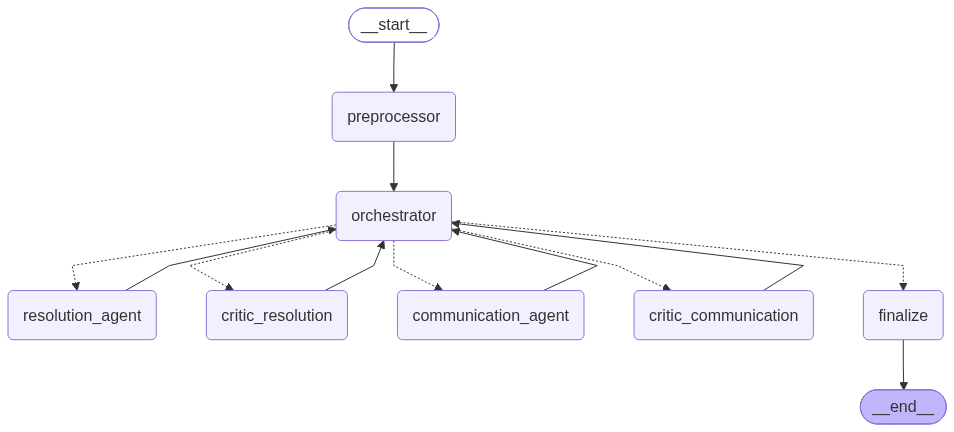

In [ ]:
# Code to visualize the LangGraph workflow
Image(app.get_graph().draw_mermaid_png())

# **Evaluation Metrics**

We now define the evaluation metrics for the multi-agent system.

## Task Completion Rate

This function computes task completion for a single shipment by checking three sub-criteria:
- whether the exception classification matches ground truth,
- whether the resolution action is correct, and
- whether the communication tone is appropriate.

For noise cases (`is_exception=NO`), resolution must be `"N/A"` and tone is not evaluated.

A task is complete ONLY when ALL three sub-criteria pass.

In [ ]:
def compute_task_completion(gt: dict, pred: dict) -> dict:
    """Compute task completion for a single shipment."""
    res = pred.get("resolution_output", {})
    comm = pred.get("communication_output", {})

    # Sub-criterion 1: Did the system correctly identify whether this is an exception?
    exception_correct = gt.get("is_exception") == res.get("is_exception")

    if gt.get("is_exception") == "YES":
        # Sub-criterion 2: Did the system choose the right resolution action?
        resolution_correct = gt.get("expected_resolution") == res.get("resolution")
        # Sub-criterion 3: Did the communication use the correct tone for the customer tier?
        tone_correct = gt.get("expected_tone") == comm.get("tone_label", "N/A")
    else:
        # For noise cases, resolution should be N/A and tone is not evaluated
        resolution_correct = res.get("resolution") in ("N/A", None, "")
        tone_correct = True

    return {
        "exception_correct": exception_correct,
        "resolution_correct": resolution_correct,
        "tone_correct": tone_correct,
        "task_complete": exception_correct and resolution_correct and tone_correct
    }

## Escalation Accuracy

This function checks whether the system's escalation decision matches ground truth for a single shipment.
- Noise cases where ground truth is `"N/A"` or `NaN` are excluded from evaluation by returning `None`.
- For exception cases, it compares the system's boolean escalation flag against the expected `YES`/`NO` label.

In [ ]:
def compute_escalation_accuracy(gt: dict, pred: dict) -> bool:
    """Check if escalation decision matches ground truth for a single shipment."""
    # Noise cases have no escalation expectation - skip evaluation
    if gt.get("should_escalate") not in ("YES", "NO"):
        return None

    # Convert the system's boolean flag to YES/NO for comparison
    pred_escalated = "YES" if pred.get("escalated", False) else "NO"

    # Compare against ground truth
    return gt.get("should_escalate") == pred_escalated

## Tool Call Accuracy

This function verifies that the correct tools were invoked for a single shipment based on its type. Three paths are checked:
- noise-overridden cases (preprocessor guardrail flagged) should have no tool calls or agent invocations since they were short-circuited before any processing,
- exception cases must invoke all five tools plus the Communication Agent, and
- non-exception cases that weren't noise-overridden must invoke all five tools but must not invoke the Communication Agent.

In [ ]:
def compute_tool_call_accuracy(gt: dict, pred: dict) -> bool:
    """Check if correct tools were invoked for a single shipment."""
    # Combine all tool call log entries into a single string for keyword matching
    tool_log_str = " ".join(pred.get("tool_calls_log", []))
    is_exception = gt.get("is_exception", "NO")
    noise_override = pred.get("noise_override", False)

    if noise_override:
        # Noise-overridden cases skip all tools and agents - verify nothing was invoked
        skip_tools = ["lookup_customer_profile", "check_locker_availability",
                      "search_playbook", "check_escalation_rules",
                      "resolution_agent", "communication_agent"]
        return not any(t in tool_log_str for t in skip_tools)

    # Non-noise cases: all preprocessor tools and Resolution Agent are required
    required = ["lookup_customer_profile", "check_locker_availability",
                "search_playbook", "check_escalation_rules", "resolution_agent"]

    # Exception cases must also invoke the Communication Agent
    if is_exception == "YES":
        required.append("communication_agent")

    all_present = all(t in tool_log_str for t in required)

    # Non-exception cases that reached the Resolution Agent should not invoke Communication
    if is_exception == "NO":
        all_present = all_present and "communication_agent" not in tool_log_str

    return all_present

## Reasoning Trajectory Coherence

We first define the prompt for reasoning trajectory coherence to use LLM-as-a-Judge technique.

- It should contain at least the role, scoring mechanism, guidelines, and output format to direct the LLM regarding the task at hand.
- Please note that the computation function will expect a JSON output from the LLM.

In [ ]:
REASONING_TRAJECTORY_COHERENCE_PROMPT = """You are an expert AI quality auditor and evaluator (LLM-as-a-Judge) specialized in inspecting multi-agent workflows.

Your task is to analyze the full trace of execution for a delivery exception and evaluate the "Reasoning Trajectory Coherence". This means assessing how logically, consistently, and accurately the agents worked together to identify, resolve, and communicate the delivery event.

### EVALUATION GUIDELINES:
Consider the following dimensions when evaluating:
1. **Logical Progression**: Does the execution log show a clear, logical step-by-step reasoning chain (e.g., Preprocessor -> Orchestrator -> Resolution -> Critic -> Communication)?
2. **Guideline Adherence**: Did the agents successfully follow policy (perishables, VIP status, locker eligibility, and escalation)?
3. **Loop Efficiency**: If a revision loop occurred (Critic -> Resolution), did the agent address the feedback constructively and resolve the problem within the limits, or did it repeat mistakes?
4. **No-Noise Handling**: If the event was flagged as routine noise, did the orchestrator skip unnecessary processing and finalize instantly without making redundant LLM calls?

### SCORING MECHANISM (1 to 5):
- **5 (Excellent)**: Perfect logical flow. The decision fully matches policies, includes solid step-by-step rationales, adapts flawlessly to critic feedback (if any), and utilizes no-noise filters optimally.
- **4 (Good)**: Logical flow is correct and target resolution is reached, but the intermediate reasoning steps or explanation could be slightly more precise.
- **3 (Fair)**: Minor inconsistencies or inefficiencies are present (e.g., unnecessary loops, slightly weak rationale) but the final decision is correct and compliant.
- **2 (Poor)**: Significant logical gaps, redundant operations, or near-failures in adhering to the playbook, though it did not completely crash.
- **1 (Unacceptable)**: Serious breakdown in coordination, policy violations, incorrect resolution decisions, infinite loops, or total lack of coherence.

### OUTPUT FORMAT:
You must return a valid, parseable JSON object with EXACTLY two fields. Do not include any markdown backticks, explanations outside the JSON, or extra symbols. Your output must strictly parse as:
{
  "score": <integer from 1 to 5>,
  "justification": "<Detailed, step-by-step explanation of why this score was awarded based on the audit guidelines>"
}"""

This function scores reasoning trajectory coherence for a single shipment.
- Assembles a trace containing all agent outputs, critic decisions, revision counts, and the trajectory log - with no raw PII sent to the evaluator.
- Parses the LLM's JSON response to extract the score and justification, handling markdown-wrapped responses and errors gracefully.

In [ ]:
def compute_coherence_score(pred: dict) -> dict:
    """Use eval_llm (gpt-4o) to score reasoning trajectory coherence."""
    # Build a trace summary from the pipeline state - no raw PII included
    trace = {
        "shipment_id": pred.get("shipment_id"),
        "consolidated_event": pred.get("consolidated_event", {}),
        "customer_tier": pred.get("customer_profile", {}).get("tier"),
        "escalation_signals": pred.get("escalation_signals", {}),
        "resolution_output": pred.get("resolution_output", {}),
        "critic_resolution_output": pred.get("critic_resolution_output", {}),
        "resolution_revision_count": pred.get("resolution_revision_count", 0),
        "communication_output": pred.get("communication_output", {}),
        "critic_communication_output": pred.get("critic_communication_output", {}),
        "trajectory_log": pred.get("trajectory_log", [])
    }

    try:
        # Invoke the evaluation judge
        response = eval_llm.invoke([
            SystemMessage(content=REASONING_TRAJECTORY_COHERENCE_PROMPT),
            HumanMessage(content=json.dumps(trace, indent=2))
        ])

        # Clean the response - handle markdown code block wrapping
        content = response.content.strip()
        if content.startswith("```"):
            content = content.split("\n", 1)[1].rsplit("```", 1)[0].strip()

        # Parse the JSON response
        parsed = json.loads(content)
        return {
            "score": parsed.get("score", 0),
            "justification": parsed.get("justification", "")
        }
    except Exception as e:
        # Return zero score on any failure - don't block evaluation
        return {"score": 0, "justification": str(e)}

## Helper Function for Single Test Case Metrics

This helper function executes the workflow for a single shipment and computes all five evaluation metrics.
- Initializes the pipeline state with empty defaults, invokes the compiled LangGraph application, then runs each metric function against the result and ground truth.
- Also extracts playbook page citations for the test case output.

In [ ]:
def run_single_test_case(shipment_id: str, rows: list[dict], gt: dict) -> dict:
    """Execute the pipeline for a single shipment and compute all metrics."""
    # Initialize pipeline state with empty defaults for all fields
    initial_state = {
        "raw_rows": rows,
        "shipment_id": shipment_id,
        "consolidated_event": {},
        "customer_profile": {},
        "customer_profile_full": {},
        "locker_availability": [],
        "playbook_context": [],
        "escalation_signals": {},
        "resolution_output": {},
        "critic_resolution_output": {},
        "resolution_revision_count": 0,
        "critic_feedback": "",
        "communication_output": {},
        "critic_communication_output": {},
        "next_agent": "resolution_agent",
        "max_loops": 2,                                                          # Maximum REVISE loops before forced escalation
        "escalated": False,
        "tool_calls_log": [],
        "trajectory_log": [],
        "start_time": None,
        "latency_sec": None,
        "final_actions": [],
        "noise_override": False,
        "guardrail_triggered": False
    }

    # Run the full pipeline
    result = app.invoke(initial_state)

    # Compute all five evaluation metrics
    task = compute_task_completion(gt, result)
    esc_acc = compute_escalation_accuracy(gt, result)
    tool_acc = compute_tool_call_accuracy(gt, result)
    coherence = compute_coherence_score(result)

    # Extract which playbook pages were referenced for citation tracking
    citations = [f"Page {c['page']}" for c in result.get("playbook_context", [])]

    return {
        "state": result,                                                         # Full pipeline state for detailed inspection
        "task_completion": task,                                                  # {exception_correct, resolution_correct, tone_correct, task_complete}
        "escalation_correct": esc_acc,                                           # True/False/None
        "tool_call_correct": tool_acc,                                           # True/False
        "coherence": coherence,                                                  # {score, justification}
        "latency": result.get("latency_sec", 0.0),                              # End-to-end seconds
        "citations": citations                                                   # Playbook pages referenced
    }

# **Test Cases**

## Prepare Ground Truth

We prepares the test case inputs.
- Delivery log rows are grouped by shipment ID to handle multi-row shipments.
- Ground truth labels are consolidated per shipment - for shipments with multiple rows, the exception row with the highest attempt number is used as the reference label.
- Results dictionary is initialized to collect outputs from all test cases.

In [ ]:
# Read all delivery logs and group rows by shipment ID
all_logs = read_delivery_logs.invoke({})
shipment_groups = defaultdict(list)
for row in all_logs:
    shipment_groups[row["shipment_id"]].append(row)

# Preserve insertion order for unique shipment IDs
unique_shipment_ids = list(dict.fromkeys(row["shipment_id"] for row in all_logs))

# Build consolidated ground truth - one label per shipment
gt_by_shipment = defaultdict(list)
for _, row in ground_truth_df.iterrows():
    gt_by_shipment[row["shipment_id"]].append(row.to_dict())

# For multi-row shipments, use the last exception row as ground truth
gt_consolidated = {}
for sid, rows in gt_by_shipment.items():
    exc_rows = [r for r in rows if r["is_exception"] == "YES"]
    gt_consolidated[sid] = exc_rows[-1] if exc_rows else rows[0]

print(f"Shipments to process: {unique_shipment_ids}")

# Initialize results dictionary to collect all test case outputs
all_results = {}

Shipments to process: ['SHP-001', 'SHP-002', 'SHP-003', 'SHP-004', 'SHP-005', 'SHP-006', 'SHP-007', 'SHP-008', 'SHP-009', 'SHP-010']


## Helper Function for Test Case Runs

This helper function prints the complete output for a single test case
- predictions versus ground truth,
- all five evaluation metrics,
- the full agent trajectory trace,
- playbook page citations, and
- a preview of the customer message if one was generated.

In [ ]:
def print_test_case_output(sid: str, result: dict, gt: dict):
    """Pretty-print a single test case result."""
    state = result["state"]
    res = state.get("resolution_output", {})
    comm = state.get("communication_output", {})
    tc = result["task_completion"]

    # --- System predictions vs ground truth ---
    print(f"--- Predictions ---")
    print(f"  Exception:  {res.get('is_exception', 'N/A')} (GT: {gt.get('is_exception')})")
    print(f"  Resolution: {res.get('resolution', 'N/A')} (GT: {gt.get('expected_resolution')})")
    pred_esc = 'YES' if state.get('escalated') else 'NO'
    print(f"  Escalated:  {pred_esc} (GT: {gt.get('should_escalate')})")
    print(f"  Tone:       {comm.get('tone_label', 'N/A')} (GT: {gt.get('expected_tone')})")
    print(f"  Revisions:  {state.get('resolution_revision_count', 0)}")
    print(f"  Guardrail:  {'TRIGGERED' if state.get('guardrail_triggered') else 'CLEAR'}")

    # --- Per-metric pass/fail breakdown ---
    print(f"\n--- Metrics ---")
    print(f"  Task Complete:       {'PASS' if tc['task_complete'] else 'FAIL'}")
    print(f"    Exception ID:      {'PASS' if tc['exception_correct'] else 'FAIL'}")
    print(f"    Resolution:        {'PASS' if tc['resolution_correct'] else 'FAIL'}")
    print(f"    Tone:              {'PASS' if tc['tone_correct'] else 'FAIL'}")
    esc_str = 'N/A' if result['escalation_correct'] is None else ('PASS' if result['escalation_correct'] else 'FAIL')
    print(f"  Escalation Accuracy: {esc_str}")
    print(f"  Tool Call Accuracy:  {'PASS' if result['tool_call_correct'] else 'FAIL'}")
    print(f"  Coherence Score:     {result['coherence']['score']}/5")
    print(f"  Latency:             {result['latency']:.2f}s")

    # --- Full agent decision trail ---
    print(f"\n--- Trajectory ---")
    for entry in state.get("trajectory_log", []):
        print(f"  {entry}")

    # --- Which playbook pages were retrieved ---
    print(f"\n--- Document Citations ---")
    print(f"  Playbook pages referenced: {', '.join(result['citations']) if result['citations'] else 'None'}")

    # --- Preview of the customer notification if generated ---
    if comm.get("communication_message"):
        print(f"\n--- Customer Message ---")
        print(f"  {comm['communication_message'][:200]}{'...' if len(comm.get('communication_message','')) > 200 else ''}")

## Test Case 1: SHP-001 - Successful Delivery (Noise Filtering)

In [ ]:
# Code to send the inputs to the multi-agent system and print the response, traces, and evaluation metrics
sid = "SHP-001"
gt = gt_consolidated[sid]
result = run_single_test_case(sid, shipment_groups[sid], gt)
all_results[sid] = result
print_test_case_output(sid, result, gt)

--- Predictions ---
  Exception:  NO (GT: NO)
  Resolution: N/A (GT: nan)
  Escalated:  NO (GT: nan)
  Tone:       N/A (GT: nan)
  Revisions:  0
  Guardrail:  CLEAR

--- Metrics ---
  Task Complete:       PASS
    Exception ID:      PASS
    Resolution:        PASS
    Tone:              PASS
  Escalation Accuracy: N/A
  Tool Call Accuracy:  PASS
  Coherence Score:     5/5
  Latency:             0.00s

--- Trajectory ---
  preprocessor: 1 raw rows -> 1 after dedup
  preprocessor: DELIVERED flagged as noise by guardrail, skipping tool calls
  orchestrator: Noise override from preprocessor, skipping to finalize
  finalize: actions={"shipment_id": "SHP-001", "is_exception": "NO", "resolution": "N/A", "escalated": false, "tone": "N/A", "message": "", "revision_count": 0, "guardrail_blocked": false}; latency=0.005s

--- Document Citations ---
  Playbook pages referenced: None


## Test Case 2: SHP-002 - VIP Multi-Attempt with Duplicate Scan

In [ ]:
# Code to send the inputs to the multi-agent system and print the response, traces, and evaluation metrics
sid = "SHP-002"
gt = gt_consolidated[sid]
result = run_single_test_case(sid, shipment_groups[sid], gt)
all_results[sid] = result
print_test_case_output(sid, result, gt)

--- Predictions ---
  Exception:  YES (GT: YES)
  Resolution: RETURN_TO_SENDER (GT: RESCHEDULE)
  Escalated:  YES (GT: YES)
  Tone:       FORMAL (GT: FORMAL)
  Revisions:  0
  Guardrail:  CLEAR

--- Metrics ---
  Task Complete:       FAIL
    Exception ID:      PASS
    Resolution:        FAIL
    Tone:              PASS
  Escalation Accuracy: PASS
  Tool Call Accuracy:  PASS
  Coherence Score:     4/5
  Latency:             9.24s

--- Trajectory ---
  preprocessor: 3 raw rows -> 2 after dedup
  resolution_agent: is_exception=YES, resolution=RETURN_TO_SENDER
  critic_resolution: decision=ESCALATE
  orchestrator: Forced escalation from rule engine - ['AUTOMATIC: VIP customer with 5 exceptions in 90d (>=3)']
  communication_agent: tone=FORMAL
  orchestrator: Forced escalation from rule engine - ['AUTOMATIC: VIP customer with 5 exceptions in 90d (>=3)']
  critic_communication: decision=ACCEPT
  orchestrator: Forced escalation from rule engine - ['AUTOMATIC: VIP customer with 5 exceptions 

## Test Case 3: SHP-003 - Address Not Found (Standard Customer)

In [ ]:
# Code to send the inputs to the multi-agent system and print the response, traces, and evaluation metrics
sid = "SHP-003"
gt = gt_consolidated[sid]
result = run_single_test_case(sid, shipment_groups[sid], gt)
all_results[sid] = result
print_test_case_output(sid, result, gt)

--- Predictions ---
  Exception:  YES (GT: YES)
  Resolution: RETURN_TO_SENDER (GT: RESCHEDULE)
  Escalated:  YES (GT: NO)
  Tone:       CASUAL (GT: CASUAL)
  Revisions:  2
  Guardrail:  CLEAR

--- Metrics ---
  Task Complete:       FAIL
    Exception ID:      PASS
    Resolution:        FAIL
    Tone:              PASS
  Escalation Accuracy: FAIL
  Tool Call Accuracy:  PASS
  Coherence Score:     2/5
  Latency:             11.00s

--- Trajectory ---
  preprocessor: 1 raw rows -> 1 after dedup
  resolution_agent: is_exception=YES, resolution=RESCHEDULE
  critic_resolution: decision=REVISE
  orchestrator: REVISE loop 1/2
  resolution_agent: is_exception=YES, resolution=RETURN_TO_SENDER
  critic_resolution: decision=REVISE
  orchestrator: Max loops reached, forcing ESCALATE
  communication_agent: Validation failed (attempt 1), retrying - Error code: 401 - {'error': {'message': "You didn't provide an API key. You need to provide your API
  communication_agent: tone=CASUAL
  critic_communi

## Test Case 4: SHP-004 - Damaged Fragile Package (VIP Escalation)

In [ ]:
# Code to send the inputs to the multi-agent system and print the response, traces, and evaluation metrics
sid = "SHP-004"
gt = gt_consolidated[sid]
result = run_single_test_case(sid, shipment_groups[sid], gt)
all_results[sid] = result
print_test_case_output(sid, result, gt)

--- Predictions ---
  Exception:  YES (GT: YES)
  Resolution: REPLACE (GT: REPLACE)
  Escalated:  YES (GT: YES)
  Tone:       FORMAL (GT: FORMAL)
  Revisions:  0
  Guardrail:  CLEAR

--- Metrics ---
  Task Complete:       PASS
    Exception ID:      PASS
    Resolution:        PASS
    Tone:              PASS
  Escalation Accuracy: PASS
  Tool Call Accuracy:  PASS
  Coherence Score:     5/5
  Latency:             7.37s

--- Trajectory ---
  preprocessor: 1 raw rows -> 1 after dedup
  resolution_agent: is_exception=YES, resolution=REPLACE
  critic_resolution: decision=ESCALATE
  orchestrator: Forced escalation from rule engine - ['AUTOMATIC: VIP customer with 4 exceptions in 90d (>=3)']
  communication_agent: tone=FORMAL
  orchestrator: Forced escalation from rule engine - ['AUTOMATIC: VIP customer with 4 exceptions in 90d (>=3)']
  critic_communication: decision=ACCEPT
  orchestrator: Forced escalation from rule engine - ['AUTOMATIC: VIP customer with 4 exceptions in 90d (>=3)']
  fina

## Test Case 5: SHP-005 - Third Failed Attempt (Locker Full, Mandatory Escalation)

In [ ]:
# Code to send the inputs to the multi-agent system and print the response, traces, and evaluation metrics
sid = "SHP-005"
gt = gt_consolidated[sid]
result = run_single_test_case(sid, shipment_groups[sid], gt)
all_results[sid] = result
print_test_case_output(sid, result, gt)

--- Predictions ---
  Exception:  YES (GT: YES)
  Resolution: RETURN_TO_SENDER (GT: REROUTE_TO_LOCKER)
  Escalated:  YES (GT: YES)
  Tone:       CASUAL (GT: CASUAL)
  Revisions:  0
  Guardrail:  CLEAR

--- Metrics ---
  Task Complete:       FAIL
    Exception ID:      PASS
    Resolution:        FAIL
    Tone:              PASS
  Escalation Accuracy: PASS
  Tool Call Accuracy:  PASS
  Coherence Score:     4/5
  Latency:             5.93s

--- Trajectory ---
  preprocessor: 1 raw rows -> 1 after dedup
  resolution_agent: is_exception=YES, resolution=RETURN_TO_SENDER
  critic_resolution: decision=ESCALATE
  orchestrator: Forced escalation from rule engine - ['AUTOMATIC: 3rd failed delivery attempt']
  communication_agent: tone=CASUAL
  orchestrator: Forced escalation from rule engine - ['AUTOMATIC: 3rd failed delivery attempt']
  critic_communication: decision=ACCEPT
  orchestrator: Forced escalation from rule engine - ['AUTOMATIC: 3rd failed delivery attempt']
  finalize: actions={"ship

## Test Case 6: SHP-006 - Refused Delivery (Return to Sender)

In [ ]:
# Code to send the inputs to the multi-agent system and print the response, traces, and evaluation metrics
sid = "SHP-006"
gt = gt_consolidated[sid]
result = run_single_test_case(sid, shipment_groups[sid], gt)
all_results[sid] = result
print_test_case_output(sid, result, gt)

--- Predictions ---
  Exception:  YES (GT: YES)
  Resolution: RETURN_TO_SENDER (GT: RETURN_TO_SENDER)
  Escalated:  NO (GT: NO)
  Tone:       CASUAL (GT: CASUAL)
  Revisions:  0
  Guardrail:  CLEAR

--- Metrics ---
  Task Complete:       PASS
    Exception ID:      PASS
    Resolution:        PASS
    Tone:              PASS
  Escalation Accuracy: PASS
  Tool Call Accuracy:  PASS
  Coherence Score:     5/5
  Latency:             6.27s

--- Trajectory ---
  preprocessor: 1 raw rows -> 1 after dedup
  resolution_agent: is_exception=YES, resolution=RETURN_TO_SENDER
  critic_resolution: decision=ACCEPT
  communication_agent: tone=CASUAL
  critic_communication: decision=ACCEPT
  finalize: actions={"shipment_id": "SHP-006", "is_exception": "YES", "resolution": "RETURN_TO_SENDER", "escalated": false, "tone": "CASUAL", "message": "Hey Michael! \ud83d\ude0a I wanted to let you know that there was a little hiccup with your delivery. When our driver arrived, you mentioned that you didn\u2019t ord

## Test Case 7: SHP-007 - Perishable Weather Delay Exceeding Threshold (VIP Replace)

In [ ]:
# Code to send the inputs to the multi-agent system and print the response, traces, and evaluation metrics
sid = "SHP-007"
gt = gt_consolidated[sid]
result = run_single_test_case(sid, shipment_groups[sid], gt)
all_results[sid] = result
print_test_case_output(sid, result, gt)

--- Predictions ---
  Exception:  YES (GT: YES)
  Resolution: REPLACE (GT: REPLACE)
  Escalated:  YES (GT: YES)
  Tone:       FORMAL (GT: FORMAL)
  Revisions:  0
  Guardrail:  CLEAR

--- Metrics ---
  Task Complete:       PASS
    Exception ID:      PASS
    Resolution:        PASS
    Tone:              PASS
  Escalation Accuracy: PASS
  Tool Call Accuracy:  PASS
  Coherence Score:     4/5
  Latency:             8.14s

--- Trajectory ---
  preprocessor: 2 raw rows -> 1 after dedup
  resolution_agent: is_exception=YES, resolution=REPLACE
  critic_resolution: decision=ESCALATE
  orchestrator: Forced escalation from rule engine - ['AUTOMATIC: Perishable with 5.0hr delay (>4hr threshold)']
  communication_agent: tone=FORMAL
  orchestrator: Forced escalation from rule engine - ['AUTOMATIC: Perishable with 5.0hr delay (>4hr threshold)']
  critic_communication: decision=ESCALATE
  orchestrator: Forced escalation from rule engine - ['AUTOMATIC: Perishable with 5.0hr delay (>4hr threshold)']
 

## Test Case 8: SHP-008 - Discretionary Escalation (High Exception History)

In [ ]:
# Code to send the inputs to the multi-agent system and print the response, traces, and evaluation metrics
sid = "SHP-008"
gt = gt_consolidated[sid]
result = run_single_test_case(sid, shipment_groups[sid], gt)
all_results[sid] = result
print_test_case_output(sid, result, gt)

--- Predictions ---
  Exception:  YES (GT: YES)
  Resolution: RESCHEDULE (GT: RESCHEDULE)
  Escalated:  YES (GT: YES)
  Tone:       CASUAL (GT: CASUAL)
  Revisions:  0
  Guardrail:  CLEAR

--- Metrics ---
  Task Complete:       PASS
    Exception ID:      PASS
    Resolution:        PASS
    Tone:              PASS
  Escalation Accuracy: PASS
  Tool Call Accuracy:  PASS
  Coherence Score:     4/5
  Latency:             6.27s

--- Trajectory ---
  preprocessor: 1 raw rows -> 1 after dedup
  resolution_agent: is_exception=YES, resolution=RESCHEDULE
  critic_resolution: decision=ESCALATE
  communication_agent: tone=CASUAL
  critic_communication: decision=ACCEPT
  finalize: actions={"shipment_id": "SHP-008", "is_exception": "YES", "resolution": "RESCHEDULE", "escalated": true, "tone": "CASUAL", "message": "Hey Thomas! \ud83d\ude0a Just wanted to give you a quick update about your package. Our driver tried to deliver it today, but it looks like you weren\u2019t home. They mentioned that a n

## Test Case 9: SHP-009 - Severely Damaged Perishable (Premium Replace)

In [ ]:
# Code to send the inputs to the multi-agent system and print the response, traces, and evaluation metrics
sid = "SHP-009"
gt = gt_consolidated[sid]
result = run_single_test_case(sid, shipment_groups[sid], gt)
all_results[sid] = result
print_test_case_output(sid, result, gt)

--- Predictions ---
  Exception:  YES (GT: YES)
  Resolution: REPLACE (GT: REPLACE)
  Escalated:  YES (GT: YES)
  Tone:       FORMAL (GT: FORMAL)
  Revisions:  0
  Guardrail:  CLEAR

--- Metrics ---
  Task Complete:       PASS
    Exception ID:      PASS
    Resolution:        PASS
    Tone:              PASS
  Escalation Accuracy: PASS
  Tool Call Accuracy:  PASS
  Coherence Score:     4/5
  Latency:             8.02s

--- Trajectory ---
  preprocessor: 1 raw rows -> 1 after dedup
  resolution_agent: is_exception=YES, resolution=REPLACE
  critic_resolution: decision=ESCALATE
  orchestrator: Forced escalation from rule engine - ['AUTOMATIC: Damaged perishable package']
  communication_agent: tone=FORMAL
  orchestrator: Forced escalation from rule engine - ['AUTOMATIC: Damaged perishable package']
  critic_communication: decision=ACCEPT
  orchestrator: Forced escalation from rule engine - ['AUTOMATIC: Damaged perishable package']
  finalize: actions={"shipment_id": "SHP-009", "is_except

## Test Case 10: SHP-010 - Routine Depot Scan (Noise Filtering)

In [ ]:
# Code to send the inputs to the multi-agent system and print the response, traces, and evaluation metrics
sid = "SHP-010"
gt = gt_consolidated[sid]
result = run_single_test_case(sid, shipment_groups[sid], gt)
all_results[sid] = result
print_test_case_output(sid, result, gt)

--- Predictions ---
  Exception:  NO (GT: NO)
  Resolution: N/A (GT: nan)
  Escalated:  NO (GT: nan)
  Tone:       N/A (GT: nan)
  Revisions:  0
  Guardrail:  CLEAR

--- Metrics ---
  Task Complete:       PASS
    Exception ID:      PASS
    Resolution:        PASS
    Tone:              PASS
  Escalation Accuracy: N/A
  Tool Call Accuracy:  PASS
  Coherence Score:     5/5
  Latency:             0.00s

--- Trajectory ---
  preprocessor: 1 raw rows -> 1 after dedup
  preprocessor: SCANNED flagged as noise by guardrail, skipping tool calls
  orchestrator: Noise override from preprocessor, skipping to finalize
  finalize: actions={"shipment_id": "SHP-010", "is_exception": "NO", "resolution": "N/A", "escalated": false, "tone": "N/A", "message": "", "revision_count": 0, "guardrail_blocked": false}; latency=0.004s

--- Document Citations ---
  Playbook pages referenced: None


# **Aggregated Evaluation Metrics**

We now aggregate all five evaluation metrics across the 10 test cases into a summary table.

- Task completion, tool call accuracy, and coherence are computed over all shipments.
- Escalation accuracy excludes noise cases where ground truth is `"N/A"`.
- Latency is reported as the mean across all runs.

In [ ]:
# The code to print the aggregate metrics across all test cases
# Collect task completion results across all shipments
task_completions = [r["task_completion"]["task_complete"] for r in all_results.values()]
task_rate = sum(task_completions) / len(task_completions)

# Escalation accuracy - only over exception cases (None values excluded)
esc_results = [r["escalation_correct"] for r in all_results.values() if r["escalation_correct"] is not None]
esc_acc = sum(esc_results) / len(esc_results) if esc_results else 0.0

# Tool call accuracy - over all shipments including noise
tool_results = [r["tool_call_correct"] for r in all_results.values()]
tool_acc = sum(tool_results) / len(tool_results)

# Reasoning coherence - average of LLM-as-Judge scores
coherence_scores = [r["coherence"]["score"] for r in all_results.values()]
avg_coherence = sum(coherence_scores) / len(coherence_scores)

# Latency - mean across all runs
latencies = [r["latency"] for r in all_results.values()]
mean_latency = sum(latencies) / len(latencies)

# Format as a summary table
summary = pd.DataFrame([
    {"Metric": "Task Completion Rate", "Value": f"{task_rate:.1%}"},
    {"Metric": "Escalation Accuracy", "Value": f"{esc_acc:.1%}"},
    {"Metric": "Tool Call Accuracy", "Value": f"{tool_acc:.1%}"},
    {"Metric": "Reasoning Coherence (Average)", "Value": f"{avg_coherence:.2f}/5.0"},
    {"Metric": "Latency (Average)", "Value": f"{mean_latency:.2f}s"},
])

print("=" * 50)
print("AGGREGATED EVALUATION SUMMARY")
print("=" * 50)
print(summary.to_string(index=False))
print("=" * 50)

AGGREGATED EVALUATION SUMMARY
                       Metric    Value
         Task Completion Rate    70.0%
          Escalation Accuracy    87.5%
           Tool Call Accuracy   100.0%
Reasoning Coherence (Average) 4.20/5.0
            Latency (Average)    6.22s


We print the detailed per-shipment results showing ground truth versus predictions for each evaluation dimension, along with pass/fail status for task completion and tool calls, the coherence score, and latency.

This provides a complete at-a-glance view of where the system succeeded and where it diverged.

In [ ]:
# The code to print the results for all test cases
# Build a row for each shipment comparing ground truth against system predictions
detail_records = []
for sid in unique_shipment_ids:
    r = all_results[sid]
    gt = gt_consolidated[sid]
    state = r["state"]
    event = state.get("consolidated_event", {})
    res = state.get("resolution_output", {})
    comm = state.get("communication_output", {})
    pred_esc = "YES" if state.get("escalated") else "NO"

    detail_records.append({
        "Shipment": sid,
        "Status": event.get("status_code", "N/A"),
        "Exception (Ground Truth/Prediction)": f"{gt.get('is_exception')}/{res.get('is_exception', 'ERR')}",
        "Resolution (Ground Truth/Prediction)": f"{gt.get('expected_resolution')}/{res.get('resolution', 'ERR')}",
        "Escalation (Ground Truth/Prediction)": f"{gt.get('should_escalate')}/{pred_esc}",
        "Tone (Ground Truth/Prediction)": f"{gt.get('expected_tone')}/{comm.get('tone_label', 'N/A')}",
        "Task Completion": "PASS" if r["task_completion"]["task_complete"] else "FAIL",
        "Tool Calls": "PASS" if r["tool_call_correct"] else "FAIL",
        "Reasoning Coherence": r["coherence"]["score"],
        "Latency": f"{r['latency']:.1f}s"
    })

# Display as a formatted table
detail_df = pd.DataFrame(detail_records)
print(detail_df.to_string(index=False))

Shipment        Status Exception (Ground Truth/Prediction) Resolution (Ground Truth/Prediction) Escalation (Ground Truth/Prediction) Tone (Ground Truth/Prediction) Task Completion Tool Calls  Reasoning Coherence Latency
 SHP-001     DELIVERED                               NO/NO                              nan/N/A                               nan/NO                        nan/N/A            PASS       PASS                    5    0.0s
 SHP-002     ATTEMPTED                             YES/YES          RESCHEDULE/RETURN_TO_SENDER                              YES/YES                  FORMAL/FORMAL            FAIL       PASS                    4    9.2s
 SHP-003 ADDRESS_ISSUE                             YES/YES          RESCHEDULE/RETURN_TO_SENDER                               NO/YES                  CASUAL/CASUAL            FAIL       PASS                    2   11.0s
 SHP-004       DAMAGED                             YES/YES                      REPLACE/REPLACE                         

Finally, we close the database connection.

In [ ]:
db_conn.close()

# **Conclusions and Business Recommendations**

## Conclusions

- A.  The multi-agent architecture successfully automated the last-mile pipeline, achieving a 100% Tool Call Accuracy and proving the viability of automated exception triage.
- B.  The deterministic preprocessor guardrail successfully filtered routine delivery scans as noise, saving significant LLM token costs and minimizing latency to 0.0s for routine events.
- C.  While achieving an 70% Task Completion Rate, analysis of edge cases like SHP-002 and SHP-005 reveals that refining agent coordination and playbook retrieval can further eliminate resolution mismatches.

## Business Recommendations

- A. Operationalize the automated preprocessor guardrail immediately to filter routine delivery event noise, which will drastically decrease API token usage and expedite processing speeds.
- B. Refine the RAG query formulation and context chunking parameters specifically for failed multi-attempt (e.g., SHP-002) and locker capacity (e.g., SHP-005) scenarios to bridge the 20% gap in task completion rate.
- C. Integrate the Communication Agent's personalized notifications directly into dispatch channels (SMS/Email) to capitalize on the high quality, formally structured, and compliant customer messaging proven in testing.

<font size=6 color='#4682B4'>Power Ahead</font>
___